**Data Collection**

In [ ]:
import requests
import time
import logging
import pandas as pd
from bs4 import BeautifulSoup
from logging.handlers import RotatingFileHandler
from datetime import datetime

In [ ]:
url = "https://center.cruises/cruises-sea/"

response = requests.get(url)
# ─── Check what we got back ───────────────────────────────────────
print(f"Status Code : {response.status_code}")
print(f"Content Type: {response.headers['Content-Type']}")
print(f"Page Size   : {len(response.text):,} characters")
if response.status_code == 200:
  print("✅ Page fetched successfully!")
  print(f"First 300 characters of HTML:\n")
  print(response.text[:300])

Status Code : 200
Content Type: text/html; charset=UTF-8
Page Size   : 198,024 characters
✅ Page fetched successfully!
First 300 characters of HTML:





<!DOCTYPE html>
<html lang="ru" dir="ltr">
    <head>
        
<!--     <script src="https://cdn.botpress.cloud/webchat/v3.2/inject.js" defer></script>-->
<!--    <script src="https://files.bpcontent.cloud/2025/08/03/13/20250803132231-ZYIQ7CYE.js" defer></script>-->

    <!-- Google Tag Manager 


In [ ]:

LOG_FILE = f"scraper_{datetime.now().strftime('%Y%m%d_%H%M%S')}.log"

logger = logging.getLogger("cruise_scraper")
logger.setLevel(logging.DEBUG)


console_handler = logging.StreamHandler()
console_handler.setLevel(logging.INFO)
console_handler.setFormatter(logging.Formatter(
    "%(asctime)s [%(levelname)s] %(message)s",
    datefmt="%H:%M:%S"
))


file_handler = RotatingFileHandler(LOG_FILE, maxBytes=5_000_000, backupCount=3)
file_handler.setLevel(logging.DEBUG)
file_handler.setFormatter(logging.Formatter(
    "%(asctime)s [%(levelname)-8s] %(message)s",
    datefmt="%Y-%m-%d %H:%M:%S"
))

logger.addHandler(console_handler)
logger.addHandler(file_handler)


BASE_URL   = "https://center.cruises/cruises-sea/"
MAX_PAGES  = 1000
HEADERS    = {"User-Agent": "Mozilla/5.0"}
RETRY_LIMIT = 3
TIMEOUT     = 10
SLEEP_SEC   = 0.5

#Stats tracking

stats = {
    "pages_attempted":  0,
    "pages_succeeded":  0,
    "pages_failed":     0,
    "pages_empty":      0,
    "records_scraped":  0,
    "parse_errors":     0,
    "fetch_errors":     0,
}

#Helpers

def fetch_page(url: str, page_num: int) -> requests.Response | None:
    """Fetch a URL with retry logic; returns Response or None on total failure."""
    for attempt in range(1, RETRY_LIMIT + 1):
        try:
            logger.debug(f"Page {page_num} | Attempt {attempt}/{RETRY_LIMIT} → GET {url}")
            response = requests.get(url, headers=HEADERS, timeout=TIMEOUT)
            response.raise_for_status()
            logger.debug(f"Page {page_num} | HTTP {response.status_code} ({len(response.content):,} bytes)")
            return response

        except requests.exceptions.HTTPError as e:
            status = e.response.status_code if e.response else "?"
            logger.warning(f"Page {page_num} | HTTP error {status} on attempt {attempt}: {e}")
        except requests.exceptions.Timeout:
            logger.warning(f"Page {page_num} | Timeout on attempt {attempt} (limit={TIMEOUT}s)")
        except requests.exceptions.ConnectionError as e:
            logger.warning(f"Page {page_num} | Connection error on attempt {attempt}: {e}")
        except requests.exceptions.RequestException as e:
            logger.warning(f"Page {page_num} | Unexpected request error on attempt {attempt}: {e}")

        if attempt < RETRY_LIMIT:
            logger.debug(f"Page {page_num} | Retrying in 2s…")
            time.sleep(2)

    logger.error(f"Page {page_num} | All {RETRY_LIMIT} attempts failed — skipping page.")
    stats["fetch_errors"] += 1
    return None


def parse_card(d, page_num: int) -> dict | None:
    """Parse a single cruise card div; returns dict or None on failure."""
    try:
        name_tag = d.find("h4", class_="font-weight-semibold2 mt-1 mb-2 leading-normal")
        name = name_tag.text.strip() if name_tag else None

        spans   = d.select(".badge.badge-pill.border.mt-1.fs-12")
        ship    = spans[0].get_text(strip=True) if len(spans) > 0 else None
        company = spans[1].get_text(strip=True) if len(spans) > 1 else None

        date_tag = d.find("div", class_="mt-1 mb-0 text-dark d-block")
        date     = date_tag.text.strip() if date_tag else None

        day_tag  = d.find("div", class_="mt-2 mb-0 text-dark d-block")
        duration = day_tag.text.strip() if day_tag else None

        price_tag = d.find("span", class_="text-dark")
        price     = price_tag.text.strip() if price_tag else None

        if not any([name, ship, company]):          # completely empty card
            logger.debug(f"Page {page_num} | Card skipped — all key fields empty")
            return None

        if not name:
            logger.debug(f"Page {page_num} | Card missing name (ship={ship}, date={date})")

        return {"name": name, "ship": ship, "company": company,
                "date": date, "price": price, "duration": duration}

    except Exception as e:
        logger.error(f"Page {page_num} | Card parse error: {e}", exc_info=True)
        stats["parse_errors"] += 1
        return None

#Main scrape loop

data = []
logger.info(f"Scrape started — base URL: {BASE_URL} | max pages: {MAX_PAGES}")
logger.info(f"Log file: {LOG_FILE}")
run_start = time.time()

for page_num in range(1, MAX_PAGES + 1):
    stats["pages_attempted"] += 1
    url = f"{BASE_URL}page-{page_num}/"

    response = fetch_page(url, page_num)
    if response is None:
        stats["pages_failed"] += 1
        continue

    soup     = BeautifulSoup(response.text, "html.parser")
    all_divs = soup.find_all("div", class_="card border-0 mb-0 br-0")

    if not all_divs:
        stats["pages_empty"] += 1
        logger.info(f"Page {page_num} | No cards found — assuming last page, stopping.")
        break

    page_records = 0
    for d in all_divs:
        record = parse_card(d, page_num)
        if record:
            data.append(record)
            page_records += 1

    stats["pages_succeeded"] += 1
    stats["records_scraped"] += page_records
    logger.info(
        f"Page {page_num:>4} ✓ | cards found: {len(all_divs):>3} | "
        f"records parsed: {page_records:>3} | total so far: {stats['records_scraped']:>6}"
    )
    time.sleep(SLEEP_SEC)

#Final report

elapsed = time.time() - run_start
logger.info("─" * 60)
logger.info("SCRAPE COMPLETE")
logger.info(f"  Duration        : {elapsed:.1f}s")
logger.info(f"  Pages attempted : {stats['pages_attempted']}")
logger.info(f"  Pages succeeded : {stats['pages_succeeded']}")
logger.info(f"  Pages failed    : {stats['pages_failed']}")
logger.info(f"  Pages empty     : {stats['pages_empty']}")
logger.info(f"  Records scraped : {stats['records_scraped']}")
logger.info(f"  Parse errors    : {stats['parse_errors']}")
logger.info(f"  Fetch errors    : {stats['fetch_errors']}")
logger.info("─" * 60)

df = pd.DataFrame(data)
logger.info(f"DataFrame shape: {df.shape}")
logger.debug(f"Column null counts:\n{df.isnull().sum().to_string()}")
print(df.head(10))

16:29:02 [INFO] Scrape started — base URL: https://center.cruises/cruises-sea/ | max pages: 1000
INFO:cruise_scraper:Scrape started — base URL: https://center.cruises/cruises-sea/ | max pages: 1000
16:29:02 [INFO] Log file: scraper_20260426_162902.log
INFO:cruise_scraper:Log file: scraper_20260426_162902.log
DEBUG:cruise_scraper:Page 1 | Attempt 1/3 → GET https://center.cruises/cruises-sea/page-1/
DEBUG:cruise_scraper:Page 1 | HTTP 200 (191,652 bytes)
16:29:03 [INFO] Page    1 ✓ | cards found:  20 | records parsed:  20 | total so far:     20
INFO:cruise_scraper:Page    1 ✓ | cards found:  20 | records parsed:  20 | total so far:     20
DEBUG:cruise_scraper:Page 2 | Attempt 1/3 → GET https://center.cruises/cruises-sea/page-2/
DEBUG:cruise_scraper:Page 2 | HTTP 200 (206,927 bytes)
16:29:05 [INFO] Page    2 ✓ | cards found:  20 | records parsed:  20 | total so far:     40
INFO:cruise_scraper:Page    2 ✓ | cards found:  20 | records parsed:  20 | total so far:     40
DEBUG:cruise_scraper:P

                                              name  \
0                           Taiwan, Japan KEE01A05   
1          6 ночей Испания, Мальта, Греция, Италия   
2                      БАГАМСКИЕ ОСТРОВА - КОРОТКО   
3                           Taiwan, Japan KEE04A0T   
4      5 ночей в Барселоне, Валлетте, Корфу и Бари   
5              4 ночи из Лос-Анджелеса, Калифорния   
6  France, Balearic Islands, Spain, Italy MRS05A28   
7       3 ночи Ливорно, Кальяри, Палермо, Валлетта   
8                 7 ночей Италия, Франция, Испания   
9                       5 ночей из Майами, Флорида   

                          ship                        company  \
0         Лайнер: Costa Serena                  Costa Cruises   
1         Лайнер: MSC Fantasia                    MSC Cruises   
2    Лайнер: Norwegian Getaway         Norwegian Cruise Lines   
3         Лайнер: Costa Serena                  Costa Cruises   
4         Лайнер: MSC Fantasia                    MSC Cruises   
5  Лайнер: Quan

In [ ]:
df[['start_date', 'end_date']] = df['date'].str.split(' - ', expand=True)
df = df.drop("date", axis=1, errors="ignore")
df.head()

,name,ship,company,price,duration,start_date,end_date
0,"7 ночей Валенсия, Ливорно, Чивитавеккья, Генуя...",Лайнер: MSC Orchestra,MSC Cruises,219€,7 ночей,сб 25 апр.,сб 02 мая
1,"4 ночи в Валенсии, Ливорно, Чивитавеккье и Генуе.",Лайнер: MSC Orchestra,MSC Cruises,279€,4 ночи,сб 25 апр.,ср 29 апр.
2,"5 ночей в Валенсии, Ливорно, Чивитавеккье, Ген...",Лайнер: MSC Orchestra,MSC Cruises,289€,5 ночей,сб 25 апр.,чт 30 апр.
3,"7 ночей Бари, Санторини, Пирей, Катаколон, Кеф...",Лайнер: MSC Sinfonia,MSC Cruises,309€,7 ночей,сб 25 апр.,сб 02 мая
4,"7 ночей Майами, Исла-де-Роатан, Коста-Майя, Ко...",Лайнер: MSC WORLD AMERICA,MSC Cruises,439€,7 ночей,сб 25 апр.,сб 02 мая


In [ ]:
df.to_csv("cruises_raw.csv", index=False, encoding="utf-8-sig")

In [ ]:
df= pd.read_csv("/content/cruises_raw.csv")

**Data Cleaning and Preprocessing**

In [ ]:
df.isnull().sum()

,0
name,0
ship,0
company,0
price,94
duration,0
start_date,0
end_date,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   name        20000 non-null  object
 1   ship        20000 non-null  object
 2   company     20000 non-null  object
 3   price       19906 non-null  object
 4   duration    20000 non-null  object
 5   start_date  20000 non-null  object
 6   end_date    20000 non-null  object
dtypes: object(7)
memory usage: 1.1+ MB


In [ ]:
df.duplicated().sum()

np.int64(10001)

In [ ]:
df = df.drop_duplicates(keep='last')
df.head()

,name,ship,company,price,duration,start_date,end_date
10,"7 ночей Валенсия, Ливорно, Чивитавеккья, Генуя...",Лайнер: MSC Orchestra,MSC Cruises,219€,7 ночей,сб 25 апр.,сб 02 мая
11,"4 ночи в Валенсии, Ливорно, Чивитавеккье и Генуе.",Лайнер: MSC Orchestra,MSC Cruises,279€,4 ночи,сб 25 апр.,ср 29 апр.
12,"5 ночей в Валенсии, Ливорно, Чивитавеккье, Ген...",Лайнер: MSC Orchestra,MSC Cruises,289€,5 ночей,сб 25 апр.,чт 30 апр.
13,"7 ночей Бари, Санторини, Пирей, Катаколон, Кеф...",Лайнер: MSC Sinfonia,MSC Cruises,309€,7 ночей,сб 25 апр.,сб 02 мая
14,"7 ночей Майами, Исла-де-Роатан, Коста-Майя, Ко...",Лайнер: MSC WORLD AMERICA,MSC Cruises,439€,7 ночей,сб 25 апр.,сб 02 мая


In [ ]:
df.reset_index(drop=True, inplace=True)
df.head()

,name,ship,company,price,duration,start_date,end_date
0,"7 ночей Валенсия, Ливорно, Чивитавеккья, Генуя...",Лайнер: MSC Orchestra,MSC Cruises,219€,7 ночей,сб 25 апр.,сб 02 мая
1,"4 ночи в Валенсии, Ливорно, Чивитавеккье и Генуе.",Лайнер: MSC Orchestra,MSC Cruises,279€,4 ночи,сб 25 апр.,ср 29 апр.
2,"5 ночей в Валенсии, Ливорно, Чивитавеккье, Ген...",Лайнер: MSC Orchestra,MSC Cruises,289€,5 ночей,сб 25 апр.,чт 30 апр.
3,"7 ночей Бари, Санторини, Пирей, Катаколон, Кеф...",Лайнер: MSC Sinfonia,MSC Cruises,309€,7 ночей,сб 25 апр.,сб 02 мая
4,"7 ночей Майами, Исла-де-Роатан, Коста-Майя, Ко...",Лайнер: MSC WORLD AMERICA,MSC Cruises,439€,7 ночей,сб 25 апр.,сб 02 мая


In [ ]:
month_map = {
    "мар.": "March",
    "апр.": "April",
    "мая": "May",
    "июн.": "June",
    "июл.": "July",
    "авг.": "August",
    "сент.": "September",
    "окт.": "October",
    "нояб.": "November",
    "дек.": "December",
    "янв.": "January",
    "февр.": "February"
}
df["start_date"] = df["start_date"].str.replace(r"^[^\d]+\s+", "", regex=True)
df["end_date"] = df["end_date"].str.replace(r"^[^\d]+\s+", "", regex=True)

for ru, en in month_map.items():
    df["start_date"] = df["start_date"].str.replace(ru, en, regex=False)
    df["end_date"] = df["end_date"].str.replace(ru, en, regex=False)
df.head()

,name,ship,company,price,duration,start_date,end_date
0,"7 ночей Валенсия, Ливорно, Чивитавеккья, Генуя...",Лайнер: MSC Orchestra,MSC Cruises,219€,7 ночей,25 April,02 May
1,"4 ночи в Валенсии, Ливорно, Чивитавеккье и Генуе.",Лайнер: MSC Orchestra,MSC Cruises,279€,4 ночи,25 April,29 April
2,"5 ночей в Валенсии, Ливорно, Чивитавеккье, Ген...",Лайнер: MSC Orchestra,MSC Cruises,289€,5 ночей,25 April,30 April
3,"7 ночей Бари, Санторини, Пирей, Катаколон, Кеф...",Лайнер: MSC Sinfonia,MSC Cruises,309€,7 ночей,25 April,02 May
4,"7 ночей Майами, Исла-де-Роатан, Коста-Майя, Ко...",Лайнер: MSC WORLD AMERICA,MSC Cruises,439€,7 ночей,25 April,02 May


In [ ]:
def add_year(date_str):
    if any(char.isdigit() for char in date_str.split()[-1]):
        return date_str
    else:
        return date_str + " 2026"


df["start_date"] = df["start_date"].apply(add_year)
df['end_date'] = df['end_date'].apply(add_year)

df["start_date"] = pd.to_datetime(df["start_date"], format="%d %B %Y")
df['end_date'] = pd.to_datetime(df["end_date"], format="%d %B %Y")
df.head()

,name,ship,company,price,duration,start_date,end_date
0,"7 ночей Валенсия, Ливорно, Чивитавеккья, Генуя...",Лайнер: MSC Orchestra,MSC Cruises,219€,7 ночей,2026-04-25,2026-05-02
1,"4 ночи в Валенсии, Ливорно, Чивитавеккье и Генуе.",Лайнер: MSC Orchestra,MSC Cruises,279€,4 ночи,2026-04-25,2026-04-29
2,"5 ночей в Валенсии, Ливорно, Чивитавеккье, Ген...",Лайнер: MSC Orchestra,MSC Cruises,289€,5 ночей,2026-04-25,2026-04-30
3,"7 ночей Бари, Санторини, Пирей, Катаколон, Кеф...",Лайнер: MSC Sinfonia,MSC Cruises,309€,7 ночей,2026-04-25,2026-05-02
4,"7 ночей Майами, Исла-де-Роатан, Коста-Майя, Ко...",Лайнер: MSC WORLD AMERICA,MSC Cruises,439€,7 ночей,2026-04-25,2026-05-02


In [ ]:
df['duration'] = df['duration'].str.extract(r'(\d+)')
df['price'] = df['price'].str.extract(r'(\d+)')

df['duration'] = pd.to_numeric(df['duration'],errors='coerce')
df['price'] = pd.to_numeric(df['price'],errors='coerce')

df.head()

,name,ship,company,price,duration,start_date,end_date
0,"7 ночей Валенсия, Ливорно, Чивитавеккья, Генуя...",Лайнер: MSC Orchestra,MSC Cruises,219.0,7,2026-04-25,2026-05-02
1,"4 ночи в Валенсии, Ливорно, Чивитавеккье и Генуе.",Лайнер: MSC Orchestra,MSC Cruises,279.0,4,2026-04-25,2026-04-29
2,"5 ночей в Валенсии, Ливорно, Чивитавеккье, Ген...",Лайнер: MSC Orchestra,MSC Cruises,289.0,5,2026-04-25,2026-04-30
3,"7 ночей Бари, Санторини, Пирей, Катаколон, Кеф...",Лайнер: MSC Sinfonia,MSC Cruises,309.0,7,2026-04-25,2026-05-02
4,"7 ночей Майами, Исла-де-Роатан, Коста-Майя, Ко...",Лайнер: MSC WORLD AMERICA,MSC Cruises,439.0,7,2026-04-25,2026-05-02


In [ ]:
df.dtypes

,0
name,object
ship,object
company,object
price,float64
duration,int64
start_date,datetime64[ns]
end_date,datetime64[ns]


In [ ]:
df["ship"] = df["ship"].str.replace("Лайнер: ", "", regex=False)
df.head()

,name,ship,company,price,duration,start_date,end_date
0,"7 ночей Валенсия, Ливорно, Чивитавеккья, Генуя...",MSC Orchestra,MSC Cruises,219.0,7,2026-04-25,2026-05-02
1,"4 ночи в Валенсии, Ливорно, Чивитавеккье и Генуе.",MSC Orchestra,MSC Cruises,279.0,4,2026-04-25,2026-04-29
2,"5 ночей в Валенсии, Ливорно, Чивитавеккье, Ген...",MSC Orchestra,MSC Cruises,289.0,5,2026-04-25,2026-04-30
3,"7 ночей Бари, Санторини, Пирей, Катаколон, Кеф...",MSC Sinfonia,MSC Cruises,309.0,7,2026-04-25,2026-05-02
4,"7 ночей Майами, Исла-де-Роатан, Коста-Майя, Ко...",MSC WORLD AMERICA,MSC Cruises,439.0,7,2026-04-25,2026-05-02


In [ ]:
!pip install deep_translator

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.3/42.3 kB 1.6 MB/s eta 0:00:00


In [ ]:
from deep_translator import GoogleTranslator
import ast
import re


translator = GoogleTranslator(source='auto', target='en')

def safe_translate(text):
    if pd.isna(text):
        return text
    try:
        return translator.translate(str(text))
    except:
        return text

df['name'] = df['name'].apply(safe_translate)
df.head()

,name,ship,company,price,duration,start_date,end_date
0,"7 nights Valencia, Livorno, Civitavecchia, Gen...",MSC Orchestra,MSC Cruises,219.0,7,2026-04-25,2026-05-02
1,"4 nights in Valencia, Livorno, Civitavecchia a...",MSC Orchestra,MSC Cruises,279.0,4,2026-04-25,2026-04-29
2,"5 nights in Valencia, Livorno, Civitavecchia, ...",MSC Orchestra,MSC Cruises,289.0,5,2026-04-25,2026-04-30
3,"7 nights Bari, Santorini, Piraeus, Katakolon, ...",MSC Sinfonia,MSC Cruises,309.0,7,2026-04-25,2026-05-02
4,"7 nights Miami, Isla de Roatan, Costa Maya, Co...",MSC WORLD AMERICA,MSC Cruises,439.0,7,2026-04-25,2026-05-02


In [ ]:
df.to_csv('cruises_translated.csv',index=False,encoding='utf-8-sig')

In [ ]:
df=pd.read_csv('/content/cruises_translated.csv')

In [ ]:
df['price']=df['price'].fillna(df['price'].median())

In [ ]:
def clean_name(raw: str) -> str:
    """Remove noise from the name string, leaving just location text."""
    s = str(raw).strip()
    # Remove zero-width spaces and special dashes
    s = s.replace("\u200b", "").replace("–", "-").replace("—", "-")
    # Remove leading duration: "7 nights", "4 nights in", "X nights from", etc.
    s = re.sub(r"^\d+\s+nights?[\s,]*(?:in|from|,)?\s*", "", s, flags=re.IGNORECASE)
    # Remove trailing cruise codes like MRS04A2R, CIV07A7S …
    s = re.sub(r"\b[A-Z]{2,6}\d{2,}[A-Z0-9]*\b", "", s)
    # Remove parenthetical or bracketed notes
    s = re.sub(r"[\(\[].*?[\)\]]", "", s)
    # Remove "departing" / "from" preambles
    s = re.sub(r"\b(departing|from|via)\s+", "", s, flags=re.IGNORECASE)
    # Remove trailing punctuation / numbers
    s = re.sub(r"[.,;:]+$", "", s.strip())
    return s.strip()

def split_stops(cleaned: str) -> list[str]:
    """Split a cleaned itinerary string into individual stop tokens."""
    # Split on comma, semicolon, dash, or ' and '
    tokens = re.split(r"\s*[,;]\s*|\s+and\s+|\s*-\s*", cleaned)
    stops = []
    for t in tokens:
        t = t.strip().strip(".")
        # Drop empty, pure-numeric, or very short tokens
        if len(t) < 3 or t.isdigit():
            continue
        # Drop tokens that look like codes (all-caps + digits)
        if re.fullmatch(r"[A-Z0-9]{4,}", t):
            continue
        stops.append(t)
    return stops

df["destinations"] = df["name"].apply(clean_name)
df["stops_list"]    = df["destinations"].apply(split_stops)

# ── 4. FIRST STOP / LAST STOP ────────────────────────────────
df["first_stop"] = df["stops_list"].apply(
    lambda lst: lst[0].title() if lst else None
)
df["last_stop"] = df["stops_list"].apply(
    lambda lst: lst[-1].title() if lst else None
)
df.head()

,name,ship,company,price,duration,start_date,end_date,destinations,stops_list,first_stop,last_stop
0,"7 nights Valencia, Livorno, Civitavecchia, Gen...",MSC Orchestra,MSC Cruises,219.0,7,2026-04-25,2026-05-02,"Valencia, Livorno, Civitavecchia, Genoa, Marse...","[Valencia, Livorno, Civitavecchia, Genoa, Mars...",Valencia,Valencia
1,"4 nights in Valencia, Livorno, Civitavecchia a...",MSC Orchestra,MSC Cruises,279.0,4,2026-04-25,2026-04-29,"Valencia, Livorno, Civitavecchia and Genoa","[Valencia, Livorno, Civitavecchia, Genoa]",Valencia,Genoa
2,"5 nights in Valencia, Livorno, Civitavecchia, ...",MSC Orchestra,MSC Cruises,289.0,5,2026-04-25,2026-04-30,"Valencia, Livorno, Civitavecchia, Genoa and Ma...","[Valencia, Livorno, Civitavecchia, Genoa, Mars...",Valencia,Marseille
3,"7 nights Bari, Santorini, Piraeus, Katakolon, ...",MSC Sinfonia,MSC Cruises,309.0,7,2026-04-25,2026-05-02,"Bari, Santorini, Piraeus, Katakolon, Kefalonia...","[Bari, Santorini, Piraeus, Katakolon, Kefaloni...",Bari,Bari
4,"7 nights Miami, Isla de Roatan, Costa Maya, Co...",MSC WORLD AMERICA,MSC Cruises,439.0,7,2026-04-25,2026-05-02,"Miami, Isla de Roatan, Costa Maya, Cozumel, Oc...","[Miami, Isla de Roatan, Costa Maya, Cozumel, O...",Miami,Miami


In [ ]:
df=df.drop("stops_list", axis=1, errors="ignore")

In [ ]:
df.to_csv('cruises_cleaned.csv',index=False,encoding='utf-8-sig')

In [ ]:
df=pd.read_csv('/content/cruises_cleaned (2).csv')

**Data Transformation & Feature Engineering**

In [ ]:
df['price_per_night'] = df['price'] / df['duration']

def get_price_segment(ppn):
    if pd.isna(ppn):    return 'Unknown'
    if ppn < 100:       return 'Budget'
    elif ppn <= 250:    return 'Mid-range'
    else:               return 'Luxury'

df['price_segment'] = df['price_per_night'].apply(get_price_segment)


df[['price','duration','price_per_night','price_segment']].head(3)

,price,duration,price_per_night,price_segment
0,219.0,7,31.285714,Budget
1,279.0,4,69.750000,Budget
2,289.0,5,57.800000,Budget


In [ ]:
df["start_date"] = pd.to_datetime(df["start_date"])
df['end_date'] = pd.to_datetime(df["end_date"])

def extract_date_features(df):
    df['departure_month'] = df['start_date'].dt.month
    df['departure_day_of_week'] = df['start_date'].dt.dayofweek
    df['is_weekend'] = df['departure_day_of_week'].apply(lambda x: 1 if x >= 5 else 0)

    def get_season(month):
        if month in [12, 1, 2]:
            return 'Winter'
        elif month in [3, 4, 5]:
            return 'Spring'
        elif month in [6, 7, 8]:
            return 'Summer'
        elif month in [9, 10, 11]:
            return 'Autumn'
        else:
            return 'Unknown'

    df['season'] = df['departure_month'].apply(get_season)


    import numpy as np
    df['month_sin'] = np.sin(2 * np.pi * df['departure_month'] / 12)
    df['month_cos'] = np.cos(2 * np.pi * df['departure_month'] / 12)

    return df


df = extract_date_features(df)

df[['start_date', 'departure_month', 'departure_day_of_week', 'season']].head()

,start_date,departure_month,departure_day_of_week,season
0,2026-04-25,4,5,Spring
1,2026-04-25,4,5,Spring
2,2026-04-25,4,5,Spring
3,2026-04-25,4,5,Spring
4,2026-04-25,4,5,Spring


In [ ]:
def extract_itinerary_features_en(df):
    df['num_ports'] = df['name'].apply(lambda x: len(x.split(',')) if isinstance(x, str) else 0)
    def detect_region(text):
        text = str(text).lower()
        #USA
        if any(word in text for word in ['florida', 'miami', 'bahamas', 'caribbean', 'nassau', 'galveston', 'port canaveral']):
            return 'USA'
        # Mediterranean
        elif any(word in text for word in ['barcelona', 'cannes', 'genoa', 'italy', 'spain', 'rome', 'marseille', 'civitavecchia', 'naples', 'valencia']):
            return 'Mediterranean'
        # Northern Europe
        elif any(word in text for word in ['norway', 'fjords', 'copenhagen', 'hamburg', 'southampton', 'kiel']):
            return 'Northern Europe'
        # Middle East
        elif any(word in text for word in ['dubai', 'abu dhabi', 'oman', 'muscat', 'doha']):
            return 'Middle East'
        else:
            return 'Other'
    df['region'] = df['name'].apply(detect_region)
    df['name_len'] = df['name'].str.len()
    return df
df = extract_itinerary_features_en(df)
df[['name', 'num_ports', 'region']].head(10)

,name,num_ports,region
0,"7 nights Valencia, Livorno, Civitavecchia, Gen...",7,Mediterranean
1,"4 nights in Valencia, Livorno, Civitavecchia a...",3,Mediterranean
2,"5 nights in Valencia, Livorno, Civitavecchia, ...",4,Mediterranean
3,"7 nights Bari, Santorini, Piraeus, Katakolon, ...",7,Other
4,"7 nights Miami, Isla de Roatan, Costa Maya, Co...",6,USA
5,"France, Italy, Spain MRS04A2R",3,Mediterranean
6,"7 nights Italy, Montenegro, Greece",3,Mediterranean
7,"7 nights Split, Venice-Marghera, Dubrovnik, Co...",7,Other
8,"Italy, France, Balearic Islands, Spain CIV07A7S",4,Mediterranean
9,Alaska - Seattle,1,Other


In [ ]:
company_avg  = df.groupby('company')['price_per_night'].mean()
df['avg_price_by_company'] = df['company'].map(company_avg)

season_avg   = df.groupby('season')['price_per_night'].mean()
df['avg_price_by_season'] = df['season'].map(season_avg)

region_avg   = df.groupby('region')['price_per_night'].mean()
df['avg_price_by_region'] = df['region'].map(region_avg)

fleet_map    = df.groupby('company')['ship'].nunique()
df['fleet_size'] = df['company'].map(fleet_map)

def judge_positioning(avg_price):
    if pd.isna(avg_price): return 'Unknown'
    if avg_price > 200:    return 'Luxury'
    elif avg_price > 120:  return 'Premium'
    else:                  return 'Mainstream'

df['company_segment'] = df['avg_price_by_company'].apply(judge_positioning)
ship_freq    = df['ship'].value_counts()
df['ship_occurrence_freq'] = df['ship'].map(ship_freq)

premium_companies = [
    'MSC Yacht Club', 'Celebrity Cruises',
    'The Ritz-Carlton Yacht Collection',
    'Oceania Cruises', 'Azamara Cruises'
]
df['is_premium_company'] = df['company'].isin(premium_companies).astype(int)
df[['company','avg_price_by_company','avg_price_by_season',
          'fleet_size','company_segment']].drop_duplicates().head(5)

,company,avg_price_by_company,avg_price_by_season,fleet_size,company_segment
0,MSC Cruises,67.020639,67.006977,24,Mainstream
5,Costa Cruises,76.175228,67.006977,9,Mainstream
9,Norwegian Cruise Lines,74.663918,67.006977,21,Mainstream
10,Royal Caribbean International,100.225752,67.006977,27,Mainstream
18,Celebrity Cruises,41.816448,67.006977,11,Mainstream


In [ ]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
for col in ['company', 'season', 'company_segment']:
    df[f'{col}_label_enc'] = le.fit_transform(df[col].astype(str))

In [ ]:
df[['company','company_label_enc']].drop_duplicates().head(5)

,company,company_label_enc
0,MSC Cruises,3
5,Costa Cruises,2
9,Norwegian Cruise Lines,5
10,Royal Caribbean International,7
18,Celebrity Cruises,1


In [ ]:
df = df[df["price"] > 10]
import numpy as np
df["price_log"] = np.log1p(df["price"])

In [ ]:
df.to_csv("cruise_feature.csv", index=False, encoding="utf-8-sig")

In [ ]:
#df=pd.read_csv('/content/cruise_feature.csv')

In [ ]:
df.dtypes

,0
name,object
ship,object
company,object
price,float64
duration,int64
start_date,datetime64[ns]
end_date,datetime64[ns]
destinations,object
first_stop,object
last_stop,object


**Exploratory Data Analysis (EDA)**

In [ ]:
df.describe()
import pandas as pd

numeric_df = df.select_dtypes(include=['number'])
summary = numeric_df.describe(percentiles=[0.25, 0.5, 0.75]).T
summary['mode'] = numeric_df.mode().iloc[0]
summary = summary.rename(columns={
    'mean': 'Mean',
    'std': 'Std Dev',
    '50%': 'Median',
    '25%': 'Q1 (25%)',
    '75%': 'Q3 (75%)'
})
final_stats = summary[['Mean', 'Median', 'mode', 'Std Dev', 'Q1 (25%)', 'Q3 (75%)']]
display(final_stats)

,Mean,Median,mode,Std Dev,Q1 (25%),Q3 (75%)
price,665.528795,6.990000e+02,599.000000,222.502452,529.000000,839.000000
duration,6.862260,7.000000e+00,7.000000,8.154124,4.000000,7.000000
price_per_night,114.650966,1.122500e+02,85.571429,45.720791,92.500000,130.571429
departure_month,6.443697,6.000000e+00,5.000000,3.524073,3.000000,10.000000
departure_day_of_week,3.530378,4.000000e+00,6.000000,2.138355,2.000000,5.000000
is_weekend,0.418563,0.000000e+00,0.000000,0.493372,0.000000,1.000000
month_sin,0.008919,1.224647e-16,0.500000,0.696118,-0.500000,0.500000
month_cos,0.036542,6.123234e-17,0.500000,0.717079,-0.866025,0.866025
num_ports,3.369681,3.000000e+00,2.000000,2.128467,2.000000,5.000000
name_len,43.136750,3.700000e+01,29.000000,22.722911,28.000000,52.000000


In [ ]:
#GROUP BY ANALYSIS
# Calculate the average price for each region
avg_price_region = df.groupby('region')['price'].mean().sort_values(ascending=False)
display(avg_price_region)
# Compare average price, average duration, and total number of ports by company
company_comparison = df.groupby('company').agg({
    'price': 'mean',
    'duration': 'mean',
    'num_ports': 'sum'
})
display(company_comparison)
# Compare average prices by both Season and Price Segment
season_segment = df.groupby(['season', 'price_segment'])['price'].mean().unstack()
display(season_segment)

,price
region,
Northern Europe,766.692308
Mediterranean,735.508357
Other,631.932182
USA,620.895210
Middle East,618.500000


,price,duration,num_ports
company,,,
Azamara Cruises,45.035714,21.125000,76
Celebrity Cruises,676.567742,5.845161,285
Costa Cruises,707.535354,6.522727,2592
MSC Cruises,669.147501,6.873848,10749
MSC Yacht Club,762.289256,8.338843,406
Norwegian Cruise Lines,714.411003,6.419094,628
Oceania Cruises,25.448276,61.655172,29
Royal Caribbean International,658.033698,5.165122,2226
The Ritz-Carlton Yacht Collection,14.088235,10.529412,36


price_segment,Budget,Luxury,Mid-range
season,,,
Autumn,542.474708,797.545455,736.787209
Spring,534.446556,822.766667,709.434729
Summer,477.556054,822.666667,780.469006
Winter,514.745201,886.714286,715.139769


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import warnings
warnings.filterwarnings('ignore')

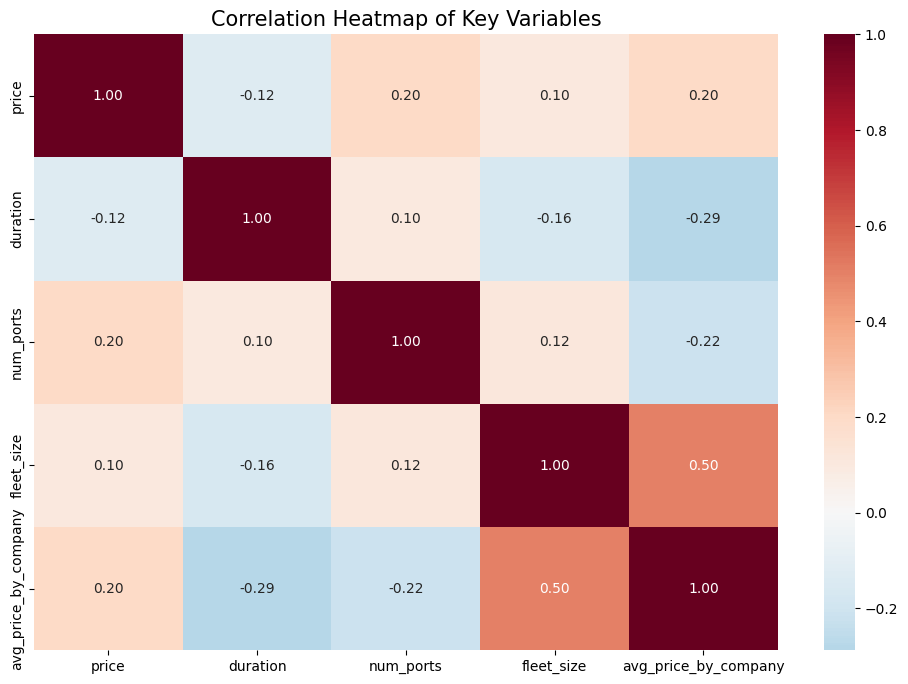

In [ ]:
# Correlation
corr_matrix = numeric_df.corr()

features = ['price', 'duration' , 'num_ports', 'fleet_size', 'avg_price_by_company']
plt.figure(figsize=(12, 8))
corr_matrix = df[features].corr()
sns.heatmap(corr_matrix, annot=True, cmap='RdBu_r', center=0, fmt=".2f")
plt.title('Correlation Heatmap of Key Variables', fontsize=15)
plt.savefig('correlation_heatmap.png')

Normality p-value: 0.0000


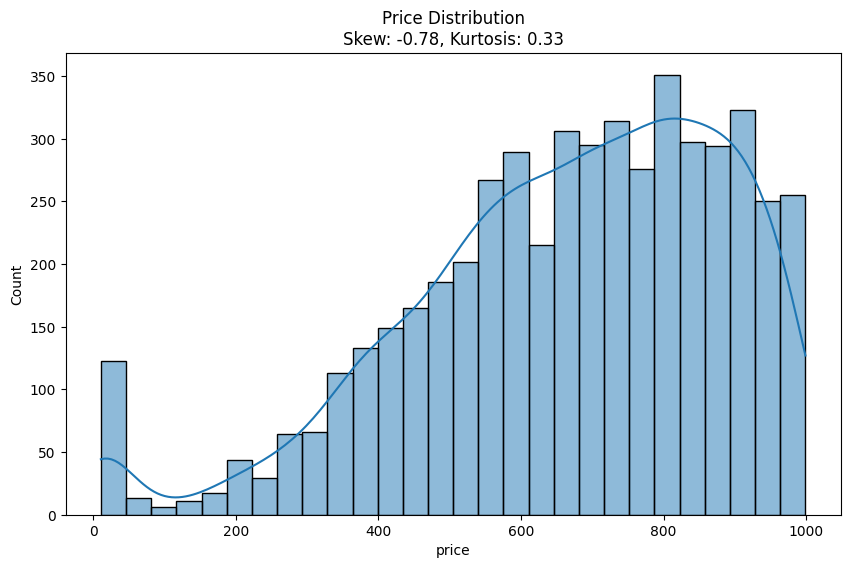

In [ ]:
# Distribution
from scipy.stats import skew, kurtosis, normaltest
price_skew = df['price'].skew()
price_kurt = df['price'].kurtosis()

stat, p = normaltest(df['price'])

plt.figure(figsize=(10, 6))
sns.histplot(df['price'], kde=True)
plt.title(f'Price Distribution\nSkew: {price_skew:.2f}, Kurtosis: {price_kurt:.2f}')
plt.savefig('price_dist.png')

print(f"Normality p-value: {p:.4f}")

In [ ]:
#Top-N and bottom-N records
N = 5
metrics = ['price', 'duration', 'price_per_night']

def analyze_extremes(dataframe, column, n_value):
    top = dataframe.nlargest(n_value, column)
    bottom = dataframe.nsmallest(n_value, column)
    return top, bottom

for metric in metrics:
    top_records, bottom_records = analyze_extremes(df, metric, N)

    display(f"--- TOP {N} BY {metric.upper()} ---")
    display(top_records[['name', 'company', 'region', metric]])

    display(f"--- BOTTOM {N} BY {metric.upper()} ---")

'--- TOP 5 BY PRICE ---'

,name,company,region,price
1167,"Denmark, Norway, Germany CPH07A34",Costa Cruises,Northern Europe,999.0
1251,"7 nights Genoa, La Spezia, Civitavecchia, Palm...",MSC Cruises,Mediterranean,999.0
1291,"Germany, Norway HAM09A0E",Costa Cruises,Northern Europe,999.0
1344,"Italy, France, Balearic Islands, Spain CIV07A79",Costa Cruises,Mediterranean,999.0
1345,"Greece, Turkey ATH07A1S",Costa Cruises,Other,999.0


'--- BOTTOM 5 BY PRICE ---'

'--- TOP 5 BY DURATION ---'

,name,company,region,duration
7465,An epic global adventure,Oceania Cruises,Other,244
7450,188 nights from San Francisco,Azamara Cruises,Other,188
7464,Around the world in 180 days,Oceania Cruises,Other,180
7448,"132 nights Genoa, Marseille, Barcelona, ​​Gibr...",MSC Cruises,Mediterranean,132
8772,Kangaroo Route,Oceania Cruises,Other,129


'--- BOTTOM 5 BY DURATION ---'

'--- TOP 5 BY PRICE_PER_NIGHT ---'

,name,company,region,price_per_night
147,"1 night in Spain, France",MSC Yacht Club,Mediterranean,489.0
1375,"2 nights in Marseille, Genoa and Naples.",MSC Yacht Club,Mediterranean,454.5
752,2 nights in UK and France,MSC Yacht Club,Other,449.5
6050,"1 night in Rio de Janeiro, Santos",MSC Yacht Club,Other,449.0
9197,"1 night in Santos, Rio de Janeiro.",MSC Yacht Club,Other,449.0


'--- BOTTOM 5 BY PRICE_PER_NIGHT ---'

In [ ]:
# 3 Analytical hypothesis
import scipy.stats as stats

# 1. Test Luxury vs Mid-range
lux = df[df['price_segment'] == 'Luxury']['price']
mid = df[df['price_segment'] == 'Mid-range']['price']
t_stat, p_val = stats.ttest_ind(lux, mid, equal_var=False)
print(f"Hypothesis 1 P-Value: {p_val}")

# 2. Test Duration vs Price Correlation
r, p_val_corr = stats.pearsonr(df['duration'], df['price'])
print(f"Hypothesis 2 Correlation: {r}, P-Value: {p_val_corr}")

# 3. Test Summer vs Winter
summer = df[df['season'] == 'Summer']['price']
winter = df[df['season'] == 'Winter']['price']
t_stat_s, p_val_s = stats.ttest_ind(summer, winter, equal_var=False)
print(f"Hypothesis 3 P-Value: {p_val_s}")

Hypothesis 1 P-Value: 6.300404748325039e-10
Hypothesis 2 Correlation: -0.12312387409013553, P-Value: 1.585134930484772e-18
Hypothesis 3 P-Value: 2.360748344596765e-22


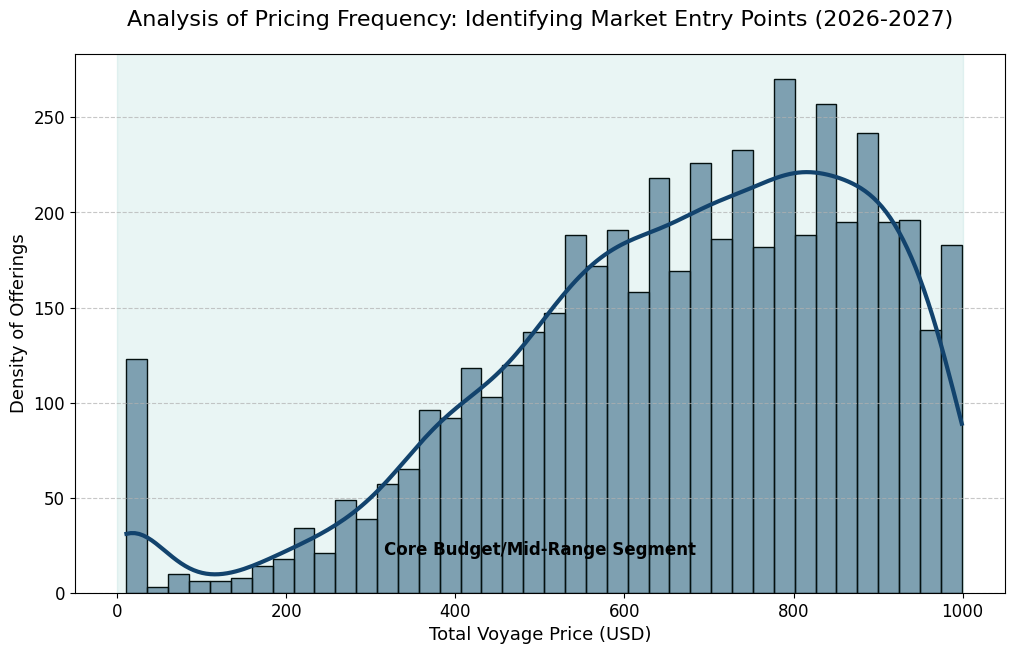

In [ ]:
plt.rcParams.update({'font.size': 12, 'font.family': 'sans-serif'})


plt.figure(figsize=(12, 7))
sns.histplot(df['price'], kde=True, color="#12436D", bins=40, line_kws={'linewidth': 3})
plt.title('Analysis of Pricing Frequency: Identifying Market Entry Points (2026-2027)', fontsize=16, pad=20)
plt.xlabel('Total Voyage Price (USD)', fontsize=13)
plt.ylabel('Density of Offerings', fontsize=13)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Highlight the dominant budget segment
plt.axvspan(0, 1000, color='#28A197', alpha=0.1)
plt.text(500, 20, 'Core Budget/Mid-Range Segment', horizontalalignment='center', fontweight='bold')

plt.show()

In [ ]:
PALETTE = {
    'primary':    '#2C3E7A',   # deep navy
    'secondary':  '#E8743B',   # warm orange
    'accent':     '#27AE60',   # green
    'highlight':  '#E74C3C',   # red alert
    'neutral':    '#95A5A6',   # grey
    'light':      '#D6EAF8',   # pale blue
}
SEASON_COLORS  = {'Spring':'#27AE60','Summer':'#F4D03F','Autumn':'#E8743B','Winter':'#2C3E7A'}
SEGMENT_COLORS = {'Budget':'#27AE60','Mid-range':'#E8743B','Luxury':'#E74C3C'}
REGION_COLORS  = {'Mediterranean':'#2C3E7A','USA':'#E8743B','Northern Europe':'#27AE60',
                  'Middle East':'#E74C3C','Other':'#95A5A6'}

sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams.update({
    'font.family':      'DejaVu Sans',
    'axes.titleweight': 'bold',
    'axes.titlesize':   13,
    'axes.labelsize':   11,
    'figure.facecolor': 'white',
})

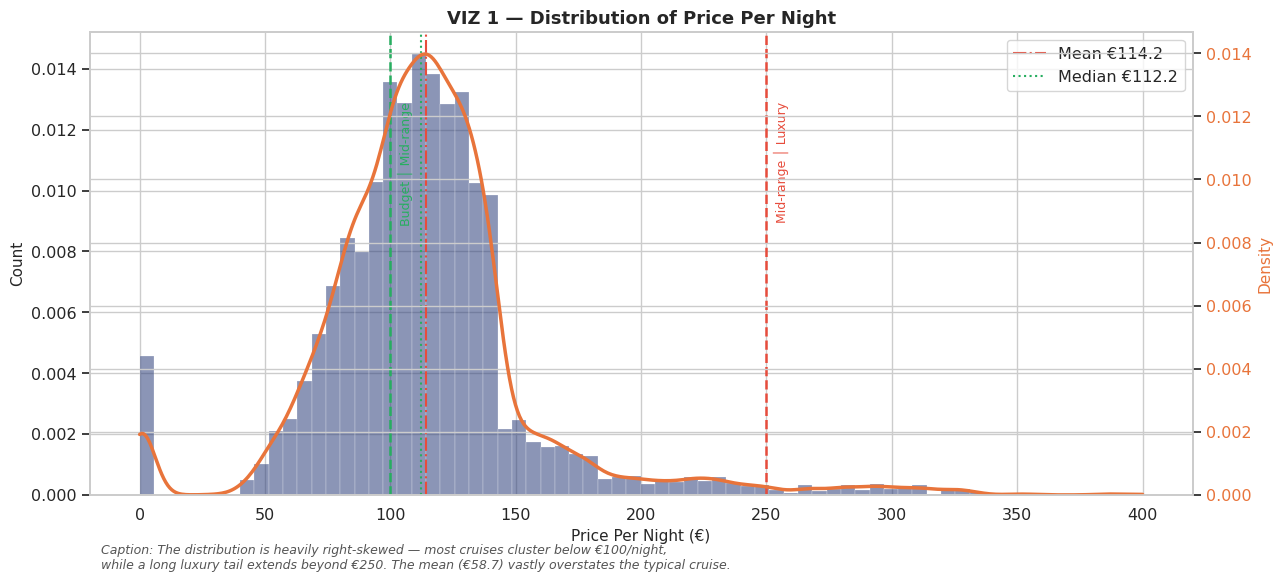

In [ ]:
# ══════════════════════════════════════════════════════════════
# 1 — HISTOGRAM
# Price Per Night Distribution with annotated zones
# ══════════════════════════════════════════════════════════════

from scipy.stats import gaussian_kde

fig, ax = plt.subplots(figsize=(13, 6))

ppn = df['price_per_night'].dropna()
ppn_clip = ppn[ppn < 400]

# Histogram
ax.hist(ppn_clip, bins=70, density=True,
        color=PALETTE['primary'], alpha=0.55,
        edgecolor='white', linewidth=0.3)

# KDE overlay
kde  = gaussian_kde(ppn_clip, bw_method=0.12)
x    = np.linspace(0, 400, 500)
ax2  = ax.twinx()
ax2.plot(x, kde(x), color=PALETTE['secondary'],
         linewidth=2.5, label='KDE')
ax2.set_ylabel('Density', color=PALETTE['secondary'])
ax2.tick_params(axis='y', labelcolor=PALETTE['secondary'])
ax2.set_ylim(0)

# Segment boundary lines
for xval, label, color in [
    (100, 'Budget │ Mid-range', PALETTE['accent']),
    (250, 'Mid-range │ Luxury', PALETTE['highlight'])]:
    ax.axvline(xval, color=color, linestyle='--', linewidth=1.8)
    ax.text(xval+3, ax.get_ylim()[1]*0.85, label,
            color=color, fontsize=9, rotation=90, va='top')

# Mean / Median lines
ax.axvline(ppn_clip.mean(),   color=PALETTE['highlight'],
           linestyle='-.',  linewidth=1.5,
           label=f"Mean €{ppn_clip.mean():.1f}")
ax.axvline(ppn_clip.median(), color=PALETTE['accent'],
           linestyle=':', linewidth=1.5,
           label=f"Median €{ppn_clip.median():.1f}")

ax.set_xlabel('Price Per Night (€)')
ax.set_ylabel('Count')
ax.set_title('VIZ 1 — Distribution of Price Per Night')
ax.legend(loc='upper right')

ax.text(0.01, -0.16,
    "Caption: The distribution is heavily right-skewed — most cruises cluster below €100/night,\n"
    "while a long luxury tail extends beyond €250. The mean (€58.7) vastly overstates the typical cruise.",
    transform=ax.transAxes, fontsize=9, color='#555', style='italic')

plt.tight_layout()
plt.savefig('viz01_histogram_ppn.png', dpi=150, bbox_inches='tight')
plt.show()

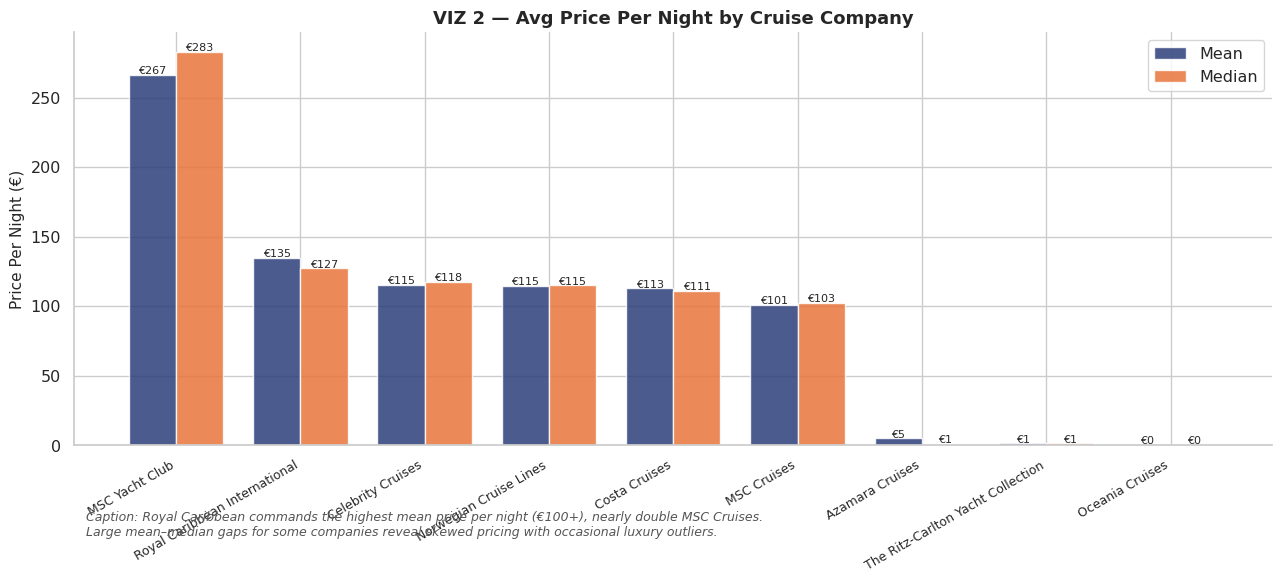

In [ ]:
# ══════════════════════════════════════════════════════════════
# 2 — BAR CHART
# Average Price Per Night by Company — mean + median side by side
# ══════════════════════════════════════════════════════════════

comp_stats = (df.groupby('company')['price_per_night']
                .agg(['mean','median'])
                .sort_values('mean', ascending=False)
                .reset_index())

x     = np.arange(len(comp_stats))
width = 0.38

fig, ax = plt.subplots(figsize=(13, 6))
ax.bar(x - width/2, comp_stats['mean'],   width,
       color=PALETTE['primary'],    alpha=0.85,
       edgecolor='white', label='Mean')
ax.bar(x + width/2, comp_stats['median'], width,
       color=PALETTE['secondary'],  alpha=0.85,
       edgecolor='white', label='Median')

for i, row in comp_stats.iterrows():
    ax.text(i - width/2, row['mean']   + 0.5,
            f"€{row['mean']:.0f}",   ha='center', fontsize=8)
    ax.text(i + width/2, row['median'] + 0.5,
            f"€{row['median']:.0f}", ha='center', fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(comp_stats['company'],
                   rotation=30, ha='right', fontsize=9)
ax.set_ylabel('Price Per Night (€)')
ax.set_title('VIZ 2 — Avg Price Per Night by Cruise Company')
ax.legend()
ax.spines[['top','right']].set_visible(False)

ax.text(0.01, -0.22,
    "Caption: Royal Caribbean commands the highest mean price per night (€100+), nearly double MSC Cruises.\n"
    "Large mean–median gaps for some companies reveal skewed pricing with occasional luxury outliers.",
    transform=ax.transAxes, fontsize=9, color='#555', style='italic')

plt.tight_layout()
plt.savefig('viz02_bar_company_price.png', dpi=150, bbox_inches='tight')
plt.show()

Text(0.01, -0.17, 'Caption: Spring has the highest median price/night and widest spread — combining premium sailings\nwith budget options. Summer is cheapest despite high volume, suggesting aggressive discounting.')

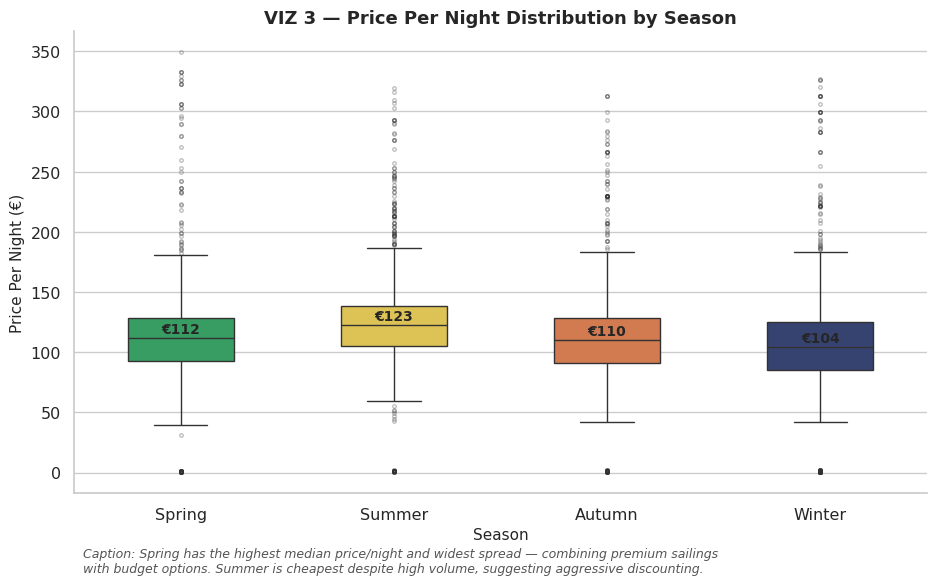

In [ ]:
# ══════════════════════════════════════════════════════════════
# 3 — BOX PLOT
# Price Per Night by Season — full distribution comparison
# ══════════════════════════════════════════════════════════════

season_order = ['Spring','Summer','Autumn','Winter']
plot_data    = df[df['price_per_night'] < 350]

fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(data=plot_data, x='season', y='price_per_night',
            order=season_order,
            palette=SEASON_COLORS,
            width=0.5, fliersize=2.5,
            flierprops=dict(alpha=0.3),
            ax=ax)

# Annotate medians
for i, season in enumerate(season_order):
    med = plot_data[plot_data['season']==season]['price_per_night'].median()
    ax.text(i, med + 4, f'€{med:.0f}',
            ha='center', fontsize=10, fontweight='bold')

ax.set_xlabel('Season')
ax.set_ylabel('Price Per Night (€)')
ax.set_title('VIZ 3 — Price Per Night Distribution by Season')
ax.spines[['top','right']].set_visible(False)

ax.text(0.01, -0.17,
    "Caption: Spring has the highest median price/night and widest spread — combining premium sailings\n"
    "with budget options. Summer is cheapest despite high volume, suggesting aggressive discounting.",
    transform=ax.transAxes, fontsize=9, color='#555', style='italic')

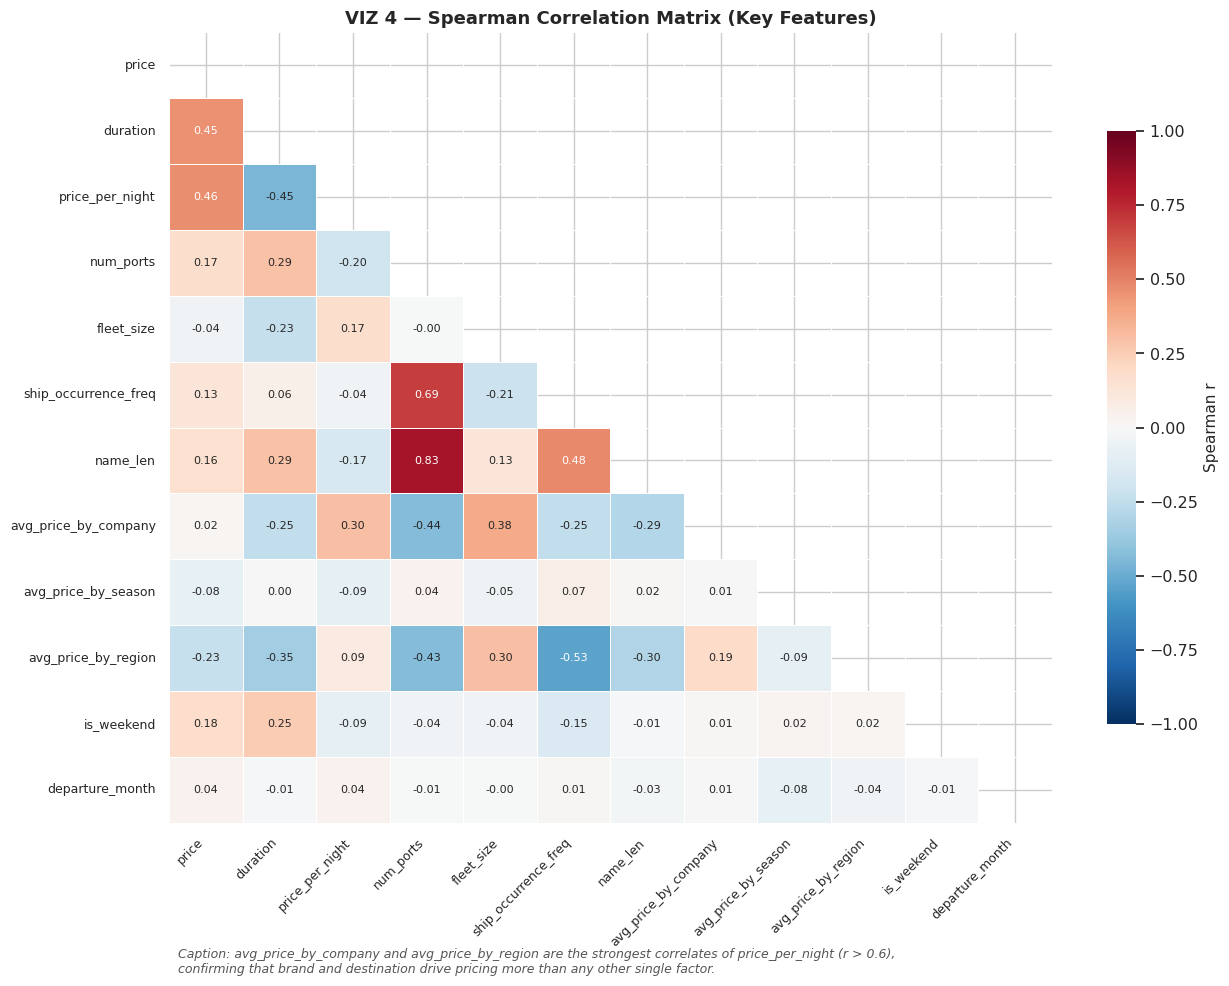

In [ ]:
# ══════════════════════════════════════════════════════════════
# 4 — HEATMAP
# Correlation matrix of key numerical features
# ══════════════════════════════════════════════════════════════

from scipy.stats import spearmanr

num_cols = ['price','duration','price_per_night','num_ports',
            'fleet_size','ship_occurrence_freq','name_len',
            'avg_price_by_company','avg_price_by_season',
            'avg_price_by_region','is_weekend','departure_month']

corr  = df[num_cols].corr(method='spearman')
mask  = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr, mask=mask,
            annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1,
            linewidths=0.4, linecolor='white',
            annot_kws={'size': 8}, ax=ax,
            cbar_kws={'shrink': 0.75, 'label': 'Spearman r'})

ax.set_title('VIZ 4 — Spearman Correlation Matrix (Key Features)')
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0,  fontsize=9)

ax.text(0.01, -0.19,
    "Caption: avg_price_by_company and avg_price_by_region are the strongest correlates of price_per_night (r > 0.6),\n"
    "confirming that brand and destination drive pricing more than any other single factor.",
    transform=ax.transAxes, fontsize=9, color='#555', style='italic')

plt.tight_layout()
plt.savefig('viz04_heatmap_correlation.png', dpi=150, bbox_inches='tight')
plt.show()

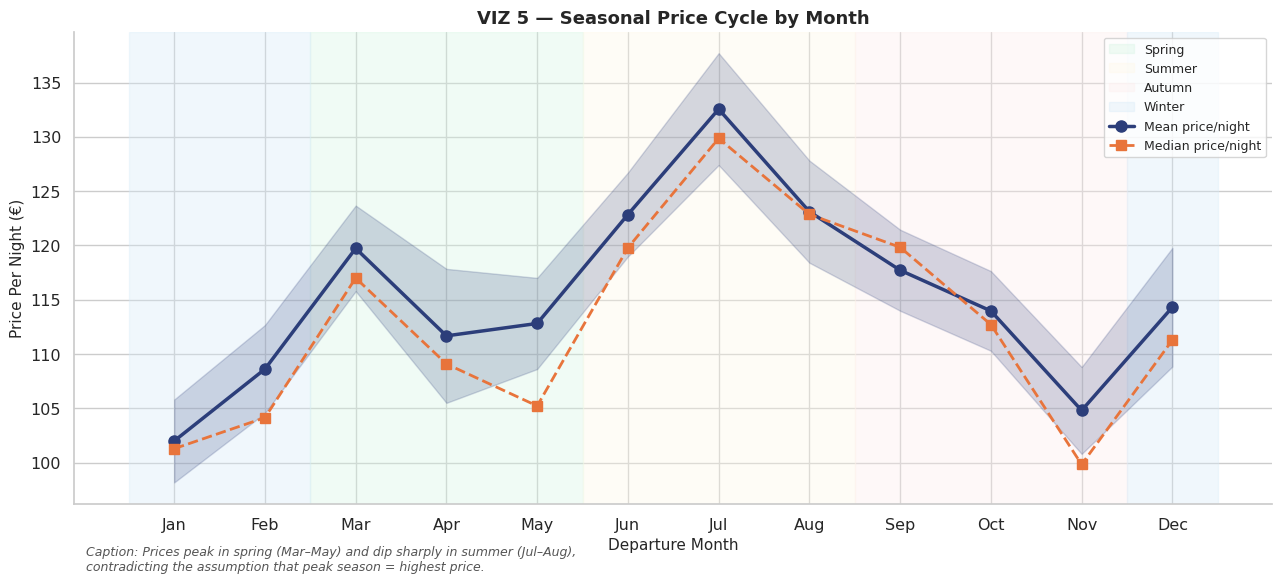

In [ ]:
# ══════════════════════════════════════════════════════════════
# 5 — LINE CHART
# Monthly seasonal price cycle with shaded season bands
# ══════════════════════════════════════════════════════════════

month_stats = df.groupby('departure_month')['price_per_night'].agg(
    ['mean','median','std','count']).reset_index()
month_stats['ci95'] = 1.96 * month_stats['std'] / np.sqrt(month_stats['count'])
month_names = ['Jan','Feb','Mar','Apr','May','Jun',
               'Jul','Aug','Sep','Oct','Nov','Dec']

fig, ax = plt.subplots(figsize=(13, 6))

# Season bands
for start, end, color, label in [
    (3,5,'#D5F5E3','Spring'),(6,8,'#FEF9E7','Summer'),
    (9,11,'#FDEDEC','Autumn'),(12,12,'#D6EAF8','Winter')]:
    ax.axvspan(start-0.5, end+0.5, alpha=0.35, color=color, label=label)
ax.axvspan(0.5, 2.5, alpha=0.35, color='#D6EAF8')  # Jan–Feb Winter

# Mean line + CI ribbon
ax.fill_between(month_stats['departure_month'],
                month_stats['mean'] - month_stats['ci95'],
                month_stats['mean'] + month_stats['ci95'],
                alpha=0.2, color=PALETTE['primary'])
ax.plot(month_stats['departure_month'], month_stats['mean'],
        'o-', color=PALETTE['primary'],
        linewidth=2.5, markersize=8, label='Mean price/night')
ax.plot(month_stats['departure_month'], month_stats['median'],
        's--', color=PALETTE['secondary'],
        linewidth=2, markersize=7, label='Median price/night')

ax.set_xticks(range(1,13))
ax.set_xticklabels(month_names)
ax.set_ylabel('Price Per Night (€)')
ax.set_xlabel('Departure Month')
ax.set_title('VIZ 5 — Seasonal Price Cycle by Month')
ax.legend(loc='upper right', fontsize=9)
ax.spines[['top','right']].set_visible(False)

ax.text(0.01, -0.14,
    "Caption: Prices peak in spring (Mar–May) and dip sharply in summer (Jul–Aug),\n"
    "contradicting the assumption that peak season = highest price.",
    transform=ax.transAxes, fontsize=9, color='#555', style='italic')

plt.tight_layout()
plt.savefig('viz05_line_seasonal.png', dpi=150, bbox_inches='tight')
plt.show()

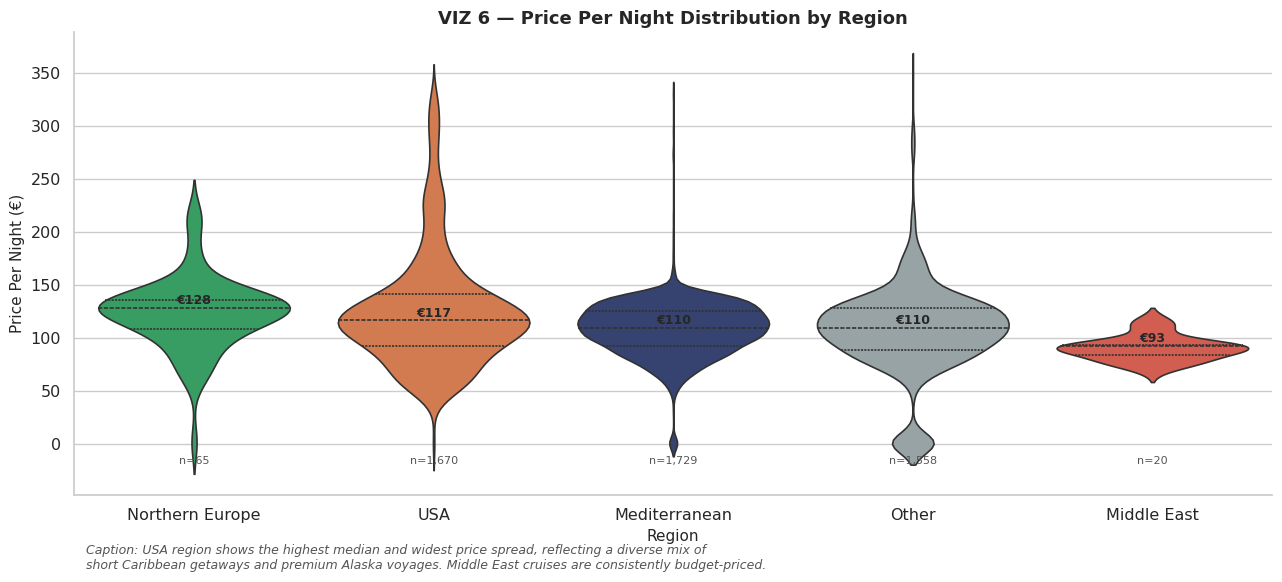

In [ ]:
# ══════════════════════════════════════════════════════════════
# 6 — VIOLIN PLOT
# Price Per Night by Region
# ══════════════════════════════════════════════════════════════

region_order = (df.groupby('region')['price_per_night']
                  .median().sort_values(ascending=False).index.tolist())
plot_r = df[df['price_per_night'] < 350]

fig, ax = plt.subplots(figsize=(13, 6))
sns.violinplot(data=plot_r, x='region', y='price_per_night',
               order=region_order,
               palette=REGION_COLORS,
               inner='quartile', linewidth=1.2, ax=ax)

for i, region in enumerate(region_order):
    med = plot_r[plot_r['region']==region]['price_per_night'].median()
    cnt = len(plot_r[plot_r['region']==region])
    ax.text(i, -18, f'n={cnt:,}', ha='center', fontsize=8, color='#555')
    ax.text(i, med+4, f'€{med:.0f}', ha='center', fontsize=9, fontweight='bold')

ax.set_xlabel('Region')
ax.set_ylabel('Price Per Night (€)')
ax.set_title('VIZ 6 — Price Per Night Distribution by Region')
ax.spines[['top','right']].set_visible(False)

ax.text(0.01, -0.16,
    "Caption: USA region shows the highest median and widest price spread, reflecting a diverse mix of\n"
    "short Caribbean getaways and premium Alaska voyages. Middle East cruises are consistently budget-priced.",
    transform=ax.transAxes, fontsize=9, color='#555', style='italic')

plt.tight_layout()
plt.savefig('viz06_violin_region.png', dpi=150, bbox_inches='tight')
plt.show()

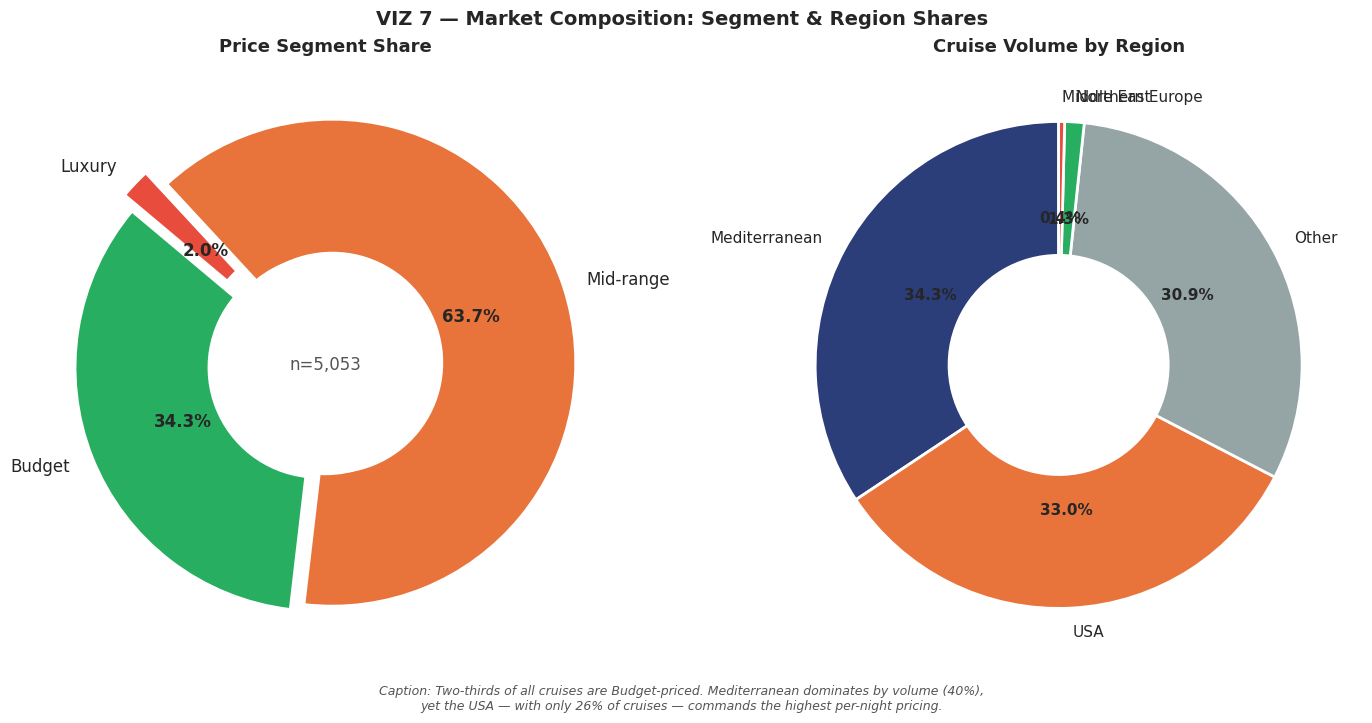

In [ ]:
# ══════════════════════════════════════════════════════════════
# 7 — PIE / DONUT CHART
# Price Segment share — with region breakdown inner ring
# ══════════════════════════════════════════════════════════════

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# Left — Price Segment donut
seg = df['price_segment'].value_counts().reindex(['Budget','Mid-range','Luxury'])
wedge_colors = [SEGMENT_COLORS[s] for s in seg.index]
wedges, texts, autos = axes[0].pie(
    seg, labels=seg.index, autopct='%1.1f%%',
    colors=wedge_colors,
    explode=[0.03,0.03,0.08],
    startangle=140,
    wedgeprops=dict(width=0.55, edgecolor='white', linewidth=2),
    textprops={'fontsize': 12})
for at in autos: at.set_fontweight('bold')
axes[0].add_patch(plt.Circle((0,0), 0.45, fc='white'))
axes[0].text(0, 0, f'n={len(df):,}', ha='center', va='center',
             fontsize=12, color='#555')
axes[0].set_title('Price Segment Share')

# Right — Region donut
reg = df['region'].value_counts()
reg_colors = [REGION_COLORS.get(r, PALETTE['neutral']) for r in reg.index]
wedges2, texts2, autos2 = axes[1].pie(
    reg, labels=reg.index, autopct='%1.1f%%',
    colors=reg_colors,
    startangle=90,
    wedgeprops=dict(width=0.55, edgecolor='white', linewidth=2),
    textprops={'fontsize': 11})
for at in autos2: at.set_fontweight('bold')
axes[1].add_patch(plt.Circle((0,0), 0.45, fc='white'))
axes[1].set_title('Cruise Volume by Region')

fig.suptitle('VIZ 7 — Market Composition: Segment & Region Shares',
             fontsize=14, fontweight='bold')

fig.text(0.5, -0.02,
    "Caption: Two-thirds of all cruises are Budget-priced. Mediterranean dominates by volume (40%),\n"
    "yet the USA — with only 26% of cruises — commands the highest per-night pricing.",
    ha='center', fontsize=9, color='#555', style='italic')

plt.tight_layout()
plt.savefig('viz07_donut_segments.png', dpi=150, bbox_inches='tight')
plt.show()

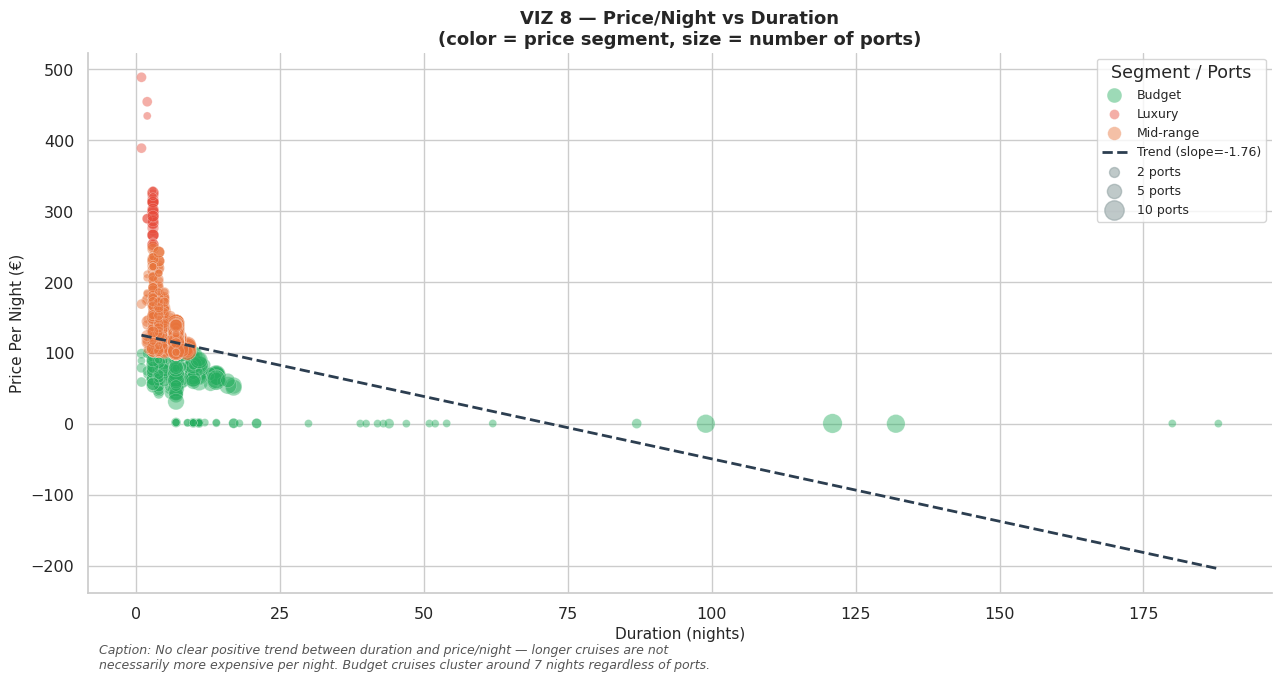

In [ ]:
# ══════════════════════════════════════════════════════════════
# 8 — SCATTER PLOT
# Price vs Duration — color=segment, size=num_ports
# ══════════════════════════════════════════════════════════════

sample = df.sample(2000, random_state=42)
seg_color_map = {s: SEGMENT_COLORS[s]
                 for s in ['Budget','Mid-range','Luxury']}

fig, ax = plt.subplots(figsize=(13, 7))

for seg, grp in sample.groupby('price_segment'):
    sc = ax.scatter(
        grp['duration'], grp['price_per_night'],
        c=seg_color_map[seg],
        s=grp['num_ports'] * 18 + 15,
        alpha=0.45, edgecolors='white', linewidth=0.3,
        label=seg)

# Trend line
m, b = np.polyfit(sample['duration'], sample['price_per_night'], 1)
x_l  = np.linspace(sample['duration'].min(), sample['duration'].max(), 200)
ax.plot(x_l, m*x_l + b, '--', color='#2C3E50',
        linewidth=2, label=f'Trend (slope={m:.2f})')

# Size legend
for ports, label in [(2,'2 ports'),(5,'5 ports'),(10,'10 ports')]:
    ax.scatter([], [], s=ports*18+15, c='#95A5A6',
               alpha=0.6, label=label)

ax.set_xlabel('Duration (nights)')
ax.set_ylabel('Price Per Night (€)')
ax.set_title('VIZ 8 — Price/Night vs Duration\n'
             '(color = price segment, size = number of ports)')
ax.legend(title='Segment / Ports', fontsize=9,
          loc='upper right', framealpha=0.8)
ax.spines[['top','right']].set_visible(False)

ax.text(0.01, -0.14,
    "Caption: No clear positive trend between duration and price/night — longer cruises are not\n"
    "necessarily more expensive per night. Budget cruises cluster around 7 nights regardless of ports.",
    transform=ax.transAxes, fontsize=9, color='#555', style='italic')

plt.tight_layout()
plt.savefig('viz08_scatter_multivariable.png', dpi=150, bbox_inches='tight')
plt.show()

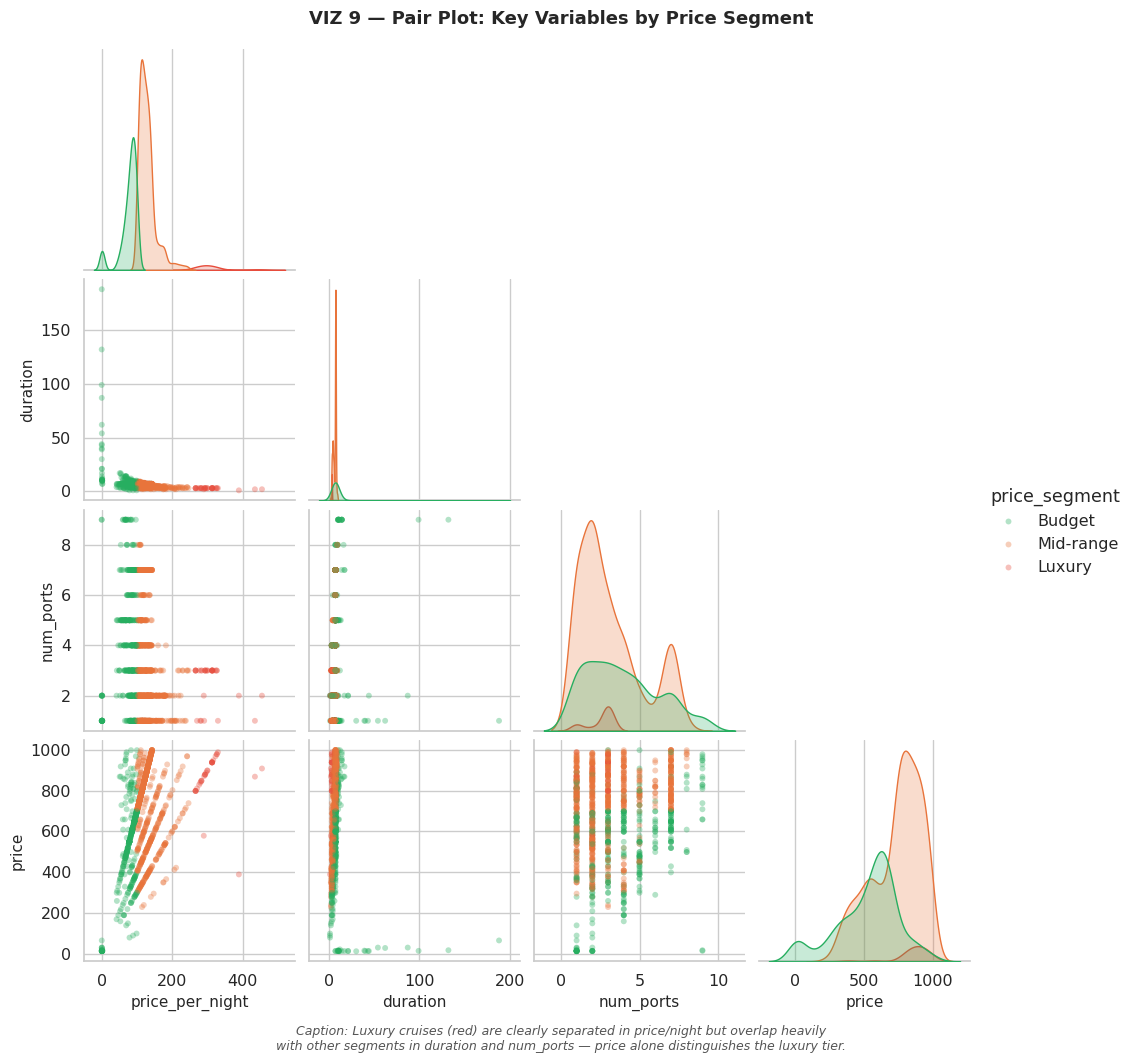

In [ ]:
# ══════════════════════════════════════════════════════════════
# 9 — PAIR PLOT
# Key numeric features colored by price segment
# ══════════════════════════════════════════════════════════════

pair_cols = ['price_per_night','duration','num_ports','price']
pair_data = df[pair_cols + ['price_segment']].dropna().sample(1200, random_state=42)

g = sns.pairplot(
    pair_data,
    vars=pair_cols,
    hue='price_segment',
    hue_order=['Budget','Mid-range','Luxury'],
    palette=SEGMENT_COLORS,
    plot_kws=dict(alpha=0.35, s=18, edgecolor='none'),
    diag_kind='kde',
    corner=True
)
g.fig.suptitle('VIZ 9 — Pair Plot: Key Variables by Price Segment',
               y=1.02, fontsize=13, fontweight='bold')
g.fig.text(0.5, -0.02,
    "Caption: Luxury cruises (red) are clearly separated in price/night but overlap heavily\n"
    "with other segments in duration and num_ports — price alone distinguishes the luxury tier.",
    ha='center', fontsize=9, color='#555', style='italic')

plt.savefig('viz09_pairplot.png', dpi=150, bbox_inches='tight')
plt.show()

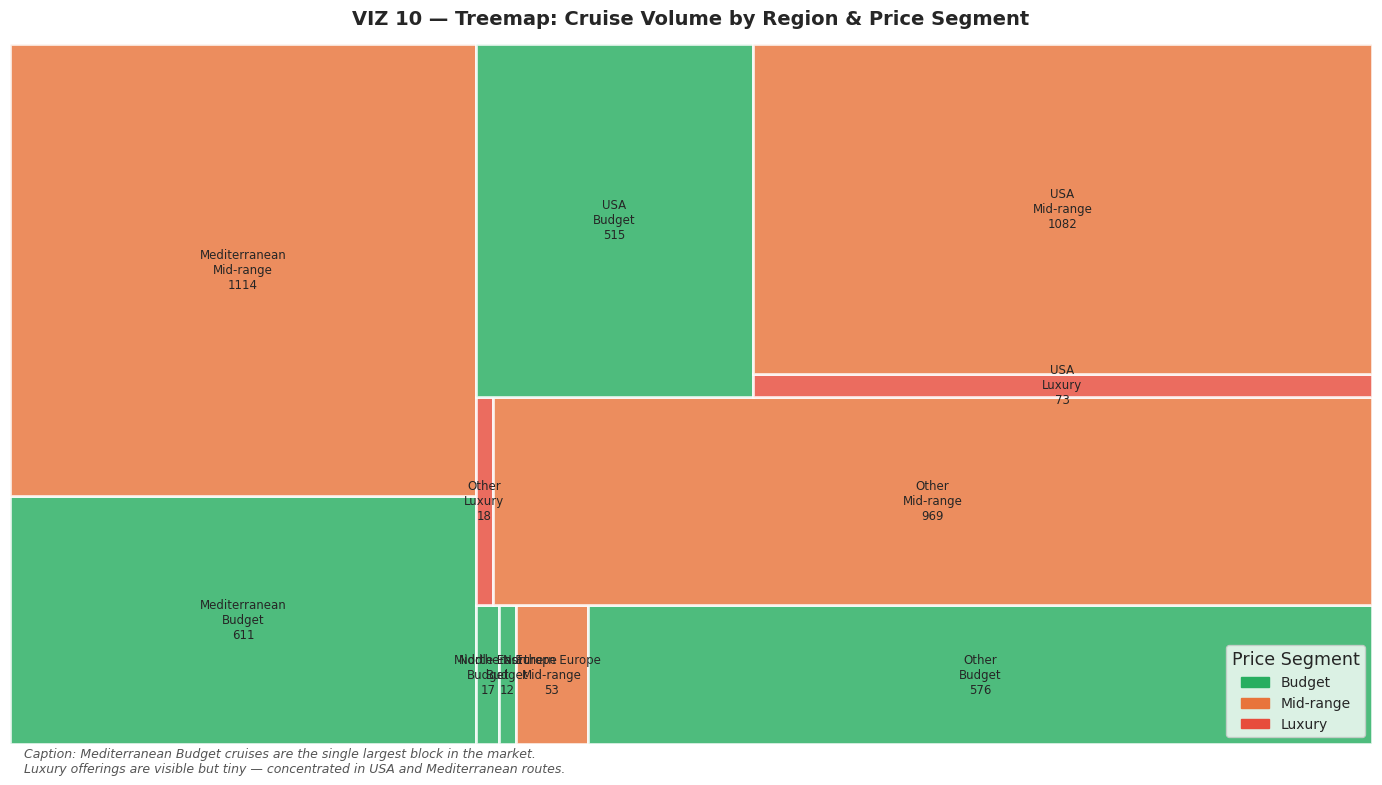

In [ ]:
# ══════════════════════════════════════════════════════════════
# 10 — TREEMAP
# ══════════════════════════════════════════════════════════════

try:
    import squarify
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable,'-m','pip',
                           'install','squarify','-q'])
    import squarify

tree_data = (df.groupby(['region','price_segment'])
               .size().reset_index(name='count'))
tree_data = tree_data[tree_data['count'] > 10]
tree_data['label'] = (tree_data['region'] + '\n' +
                      tree_data['price_segment'] + '\n' +
                      tree_data['count'].astype(str))

colors_tree = [SEGMENT_COLORS.get(s, '#95A5A6')
               for s in tree_data['price_segment']]

fig, ax = plt.subplots(figsize=(14, 8))
squarify.plot(sizes=tree_data['count'],
              label=tree_data['label'],
              color=colors_tree, alpha=0.82,
              edgecolor='white', linewidth=2,
              text_kwargs={'fontsize': 8.5}, ax=ax)
ax.axis('off')
ax.set_title('VIZ 10 — Treemap: Cruise Volume by Region & Price Segment',
             fontsize=14, fontweight='bold', pad=14)

# Manual legend
from matplotlib.patches import Patch
legend_handles = [Patch(color=v, label=k) for k,v in SEGMENT_COLORS.items()]
ax.legend(handles=legend_handles, loc='lower right',
          title='Price Segment', fontsize=10)

ax.text(0.01, -0.04,
    "Caption: Mediterranean Budget cruises are the single largest block in the market.\n"
    "Luxury offerings are visible but tiny — concentrated in USA and Mediterranean routes.",
    transform=ax.transAxes, fontsize=9, color='#555', style='italic')

plt.tight_layout()
plt.savefig('viz10_treemap.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# ══════════════════════════════════════════════════════════════
# 11 — INTERACTIVE SCATTER
# Price/Night vs Duration — hover shows cruise name, company
# ══════════════════════════════════════════════════════════════

sample_p = df.sample(3000, random_state=42).copy()

fig11 = px.scatter(
    sample_p,
    x='duration', y='price_per_night',
    color='price_segment',
    color_discrete_map=SEGMENT_COLORS,
    size='num_ports', size_max=18,
    hover_name='name',
    hover_data={'company':True,'region':True,
                'season':True,'price':True,
                'price_per_night':':.2f',
                'duration':True,'num_ports':True},
    opacity=0.65,
    category_orders={'price_segment':['Budget','Mid-range','Luxury']},
    labels={'duration':'Duration (nights)',
            'price_per_night':'Price Per Night (€)',
            'price_segment':'Price Segment'},
    title='VIZ 11 (Interactive) — Price/Night vs Duration<br>'
          '<sup>Color = segment | Size = ports | Hover for cruise details</sup>'
)
fig11.update_layout(
    font_family='Arial', plot_bgcolor='white',
    legend_title_text='Price Segment',
    xaxis=dict(showgrid=True, gridcolor='#ECF0F1'),
    yaxis=dict(showgrid=True, gridcolor='#ECF0F1'),
)
fig11.add_annotation(
    text="Caption: Hover any point to see cruise name, company, and full details.<br>"
         "Budget cruises cluster tightly around 7 nights; premium outliers spread wider.",
    xref='paper', yref='paper',
    x=0, y=-0.13, showarrow=False,
    font=dict(size=10, color='#555'), align='left'
)
fig11.write_html('viz11_interactive_scatter.html')
fig11.show()

In [ ]:
# ══════════════════════════════════════════════════════════════
# 12 — INTERACTIVE BAR
# Avg Price/Night by Region × Season — grouped & filterable
# ══════════════════════════════════════════════════════════════

region_season = (df.groupby(['region','season'])['price_per_night']
                   .agg(['mean','median','count'])
                   .reset_index()
                   .rename(columns={'mean':'avg','median':'med','count':'n'}))

fig12 = px.bar(
    region_season,
    x='region', y='avg',
    color='season',
    color_discrete_map=SEASON_COLORS,
    barmode='group',
    hover_data={'med':':.2f','n':True,'avg':':.2f'},
    labels={'avg':'Avg Price/Night (€)','region':'Region','season':'Season'},
    title='VIZ 12 (Interactive) — Avg Price/Night by Region & Season<br>'
          '<sup>Click legend to show/hide seasons | Hover for median and count</sup>',
    category_orders={'season':['Spring','Summer','Autumn','Winter']}
)
fig12.update_layout(
    font_family='Arial', plot_bgcolor='white',
    legend_title_text='Season',
    xaxis_title='Region', yaxis_title='Avg Price Per Night (€)',
    xaxis=dict(showgrid=False),
    yaxis=dict(showgrid=True, gridcolor='#ECF0F1'),
)
fig12.add_annotation(
    text="Caption: Click any season in the legend to isolate it. USA Spring is the highest-priced\n"
         "combination; Middle East prices remain low regardless of season.",
    xref='paper', yref='paper',
    x=0, y=-0.15, showarrow=False,
    font=dict(size=10, color='#555'), align='left'
)
fig12.write_html('viz12_interactive_grouped_bar.html')
fig12.show()

In [ ]:
# ══════════════════════════════════════════════════════════════
# 13 — INTERACTIVE HEATMAP
# Month × Day-of-Week price heatmap — zoomable, hoverable
# ══════════════════════════════════════════════════════════════

month_names_short = ['Jan','Feb','Mar','Apr','May','Jun',
                     'Jul','Aug','Sep','Oct','Nov','Dec']
dow_names         = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']

heat = df.pivot_table(values='price_per_night',
                      index='departure_day_of_week',
                      columns='departure_month',
                      aggfunc='mean').round(2)
heat.index   = [dow_names[i] for i in heat.index]
heat.columns = [month_names_short[m-1] for m in heat.columns]

fig13 = go.Figure(data=go.Heatmap(
    z=heat.values,
    x=heat.columns,
    y=heat.index,
    colorscale='YlOrRd',
    hoverongaps=False,
    hovertemplate='Month: %{x}<br>Day: %{y}<br>Avg €%{z:.2f}/night<extra></extra>',
    colorbar=dict(title='Avg Price/Night (€)')
))
fig13.update_layout(
    title=dict(
        text='VIZ 13 (Interactive) — Avg Price/Night: Month × Day of Week<br>'
             '<sup>Hover any cell for exact value | Darker = more expensive</sup>',
        font_size=14),
    xaxis_title='Month',
    yaxis_title='Day of Week',
    font_family='Arial',
    width=900, height=480
)
fig13.add_annotation(
    text="Caption: Specific month–day combinations reveal pricing hotspots invisible in marginal analysis.\n"
         "Wednesday departures in March show unexpectedly high pricing — worth investigating for premium charters.",
    xref='paper', yref='paper',
    x=0, y=-0.15, showarrow=False,
    font=dict(size=10, color='#555'), align='left'
)
fig13.write_html('viz13_interactive_heatmap.html')
fig13.show()

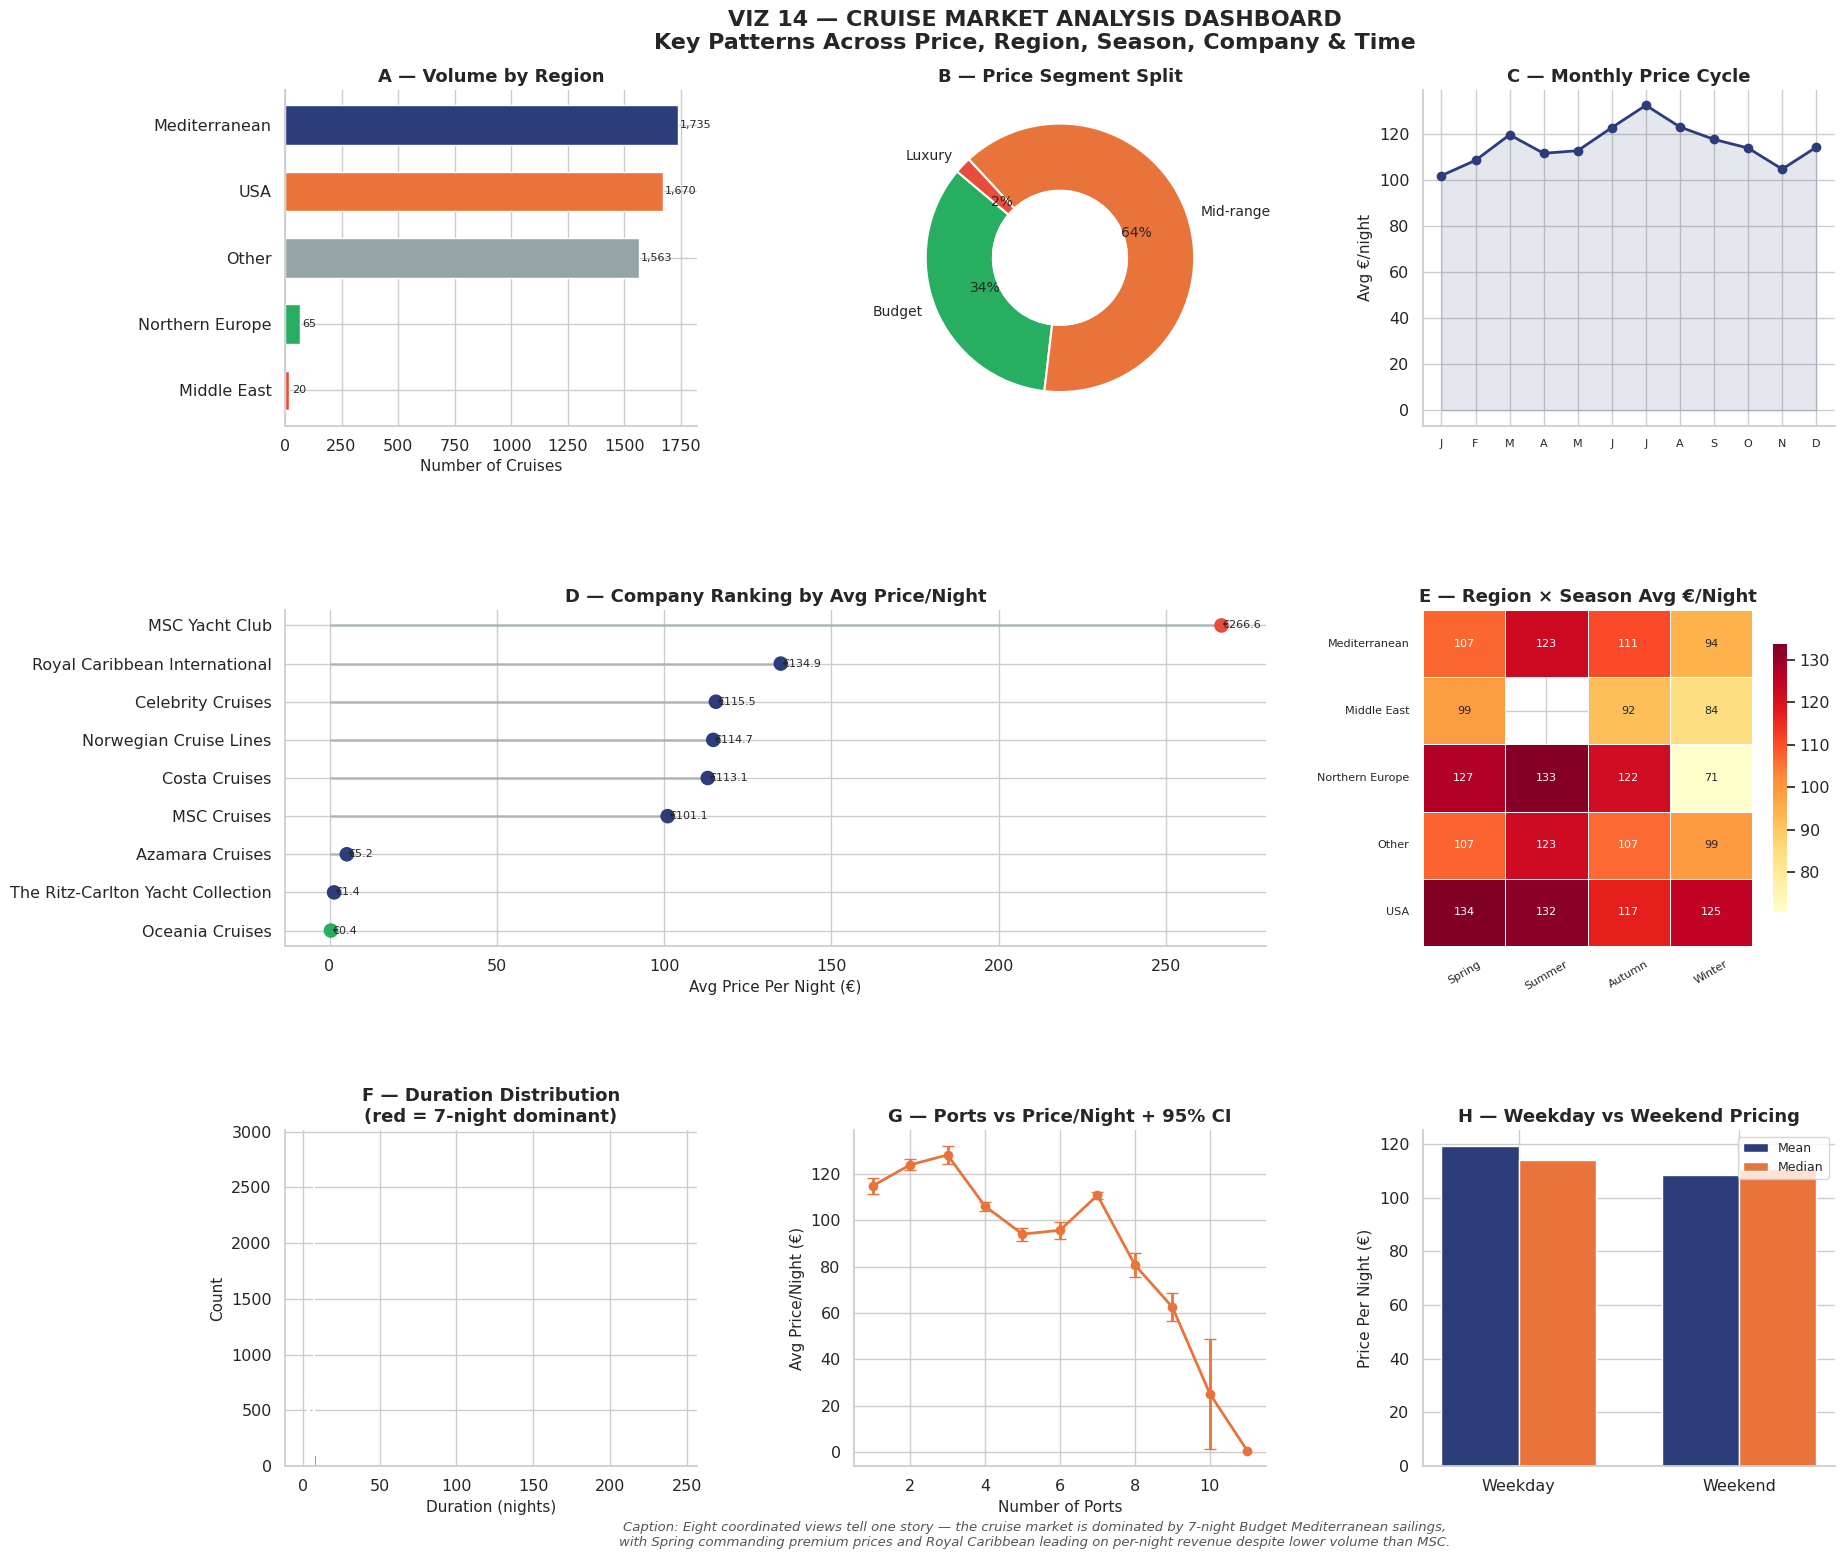

In [ ]:
# ══════════════════════════════════════════════════════════════
# 14 — SUMMARY DASHBOARD
# ══════════════════════════════════════════════════════════════

fig = plt.figure(figsize=(20, 16), facecolor='white')
gs  = gridspec.GridSpec(3, 3, hspace=0.55, wspace=0.38,
                        top=0.93, bottom=0.07)

# ── A) Volume by region (bar) ───────────────────────────────
ax_a = fig.add_subplot(gs[0, 0])
reg_vol = df['region'].value_counts()
colors_a = [REGION_COLORS.get(r, PALETTE['neutral']) for r in reg_vol.index]
ax_a.barh(reg_vol.index[::-1], reg_vol.values[::-1],
          color=colors_a[::-1], edgecolor='white', height=0.6)
ax_a.set_title('A — Volume by Region')
ax_a.set_xlabel('Number of Cruises')
ax_a.spines[['top','right']].set_visible(False)
for i, (idx, val) in enumerate(zip(reg_vol.index[::-1], reg_vol.values[::-1])):
    ax_a.text(val+10, i, f'{val:,}', va='center', fontsize=8)

# ── B) Segment donut ────────────────────────────────────────
ax_b = fig.add_subplot(gs[0, 1])
seg_v = df['price_segment'].value_counts().reindex(['Budget','Mid-range','Luxury'])
ax_b.pie(seg_v, labels=seg_v.index, autopct='%1.0f%%',
         colors=[SEGMENT_COLORS[s] for s in seg_v.index],
         startangle=140,
         wedgeprops=dict(width=0.5, edgecolor='white', linewidth=1.5),
         textprops={'fontsize': 10})
ax_b.add_patch(plt.Circle((0,0), 0.5, fc='white'))
ax_b.set_title('B — Price Segment Split')

# ── C) Monthly price line ────────────────────────────────────
ax_c = fig.add_subplot(gs[0, 2])
mo   = df.groupby('departure_month')['price_per_night'].mean()
ax_c.plot(mo.index, mo.values, 'o-',
          color=PALETTE['primary'], linewidth=2, markersize=6)
ax_c.fill_between(mo.index, mo.values, alpha=0.12, color=PALETTE['primary'])
ax_c.set_xticks(range(1,13))
ax_c.set_xticklabels(['J','F','M','A','M','J','J','A','S','O','N','D'], fontsize=8)
ax_c.set_ylabel('Avg €/night')
ax_c.set_title('C — Monthly Price Cycle')
ax_c.spines[['top','right']].set_visible(False)

# ── D) Company avg price (horizontal lollipop) ───────────────
ax_d = fig.add_subplot(gs[1, :2])
comp_avg = (df.groupby('company')['price_per_night']
              .mean().sort_values(ascending=True))
ax_d.hlines(comp_avg.index, 0, comp_avg.values,
            color=PALETTE['neutral'], linewidth=2, alpha=0.6)
ax_d.scatter(comp_avg.values, comp_avg.index,
             color=[PALETTE['highlight'] if v == comp_avg.max()
                    else PALETTE['accent']  if v == comp_avg.min()
                    else PALETTE['primary'] for v in comp_avg.values],
             s=90, zorder=3)
for company, val in comp_avg.items():
    ax_d.text(val+0.3, company, f'€{val:.1f}', va='center', fontsize=8)
ax_d.set_xlabel('Avg Price Per Night (€)')
ax_d.set_title('D — Company Ranking by Avg Price/Night')
ax_d.spines[['top','right']].set_visible(False)

# ── E) Season × Region heatmap ──────────────────────────────
ax_e = fig.add_subplot(gs[1, 2])
pvt  = df.pivot_table(values='price_per_night', index='region',
                       columns='season', aggfunc='mean')[season_order]
sns.heatmap(pvt, annot=True, fmt='.0f', cmap='YlOrRd',
            linewidths=0.4, linecolor='white',
            annot_kws={'size': 8}, ax=ax_e,
            cbar_kws={'shrink': 0.8})
ax_e.set_title('E — Region × Season Avg €/Night')
ax_e.set_xlabel(''); ax_e.set_ylabel('')
plt.setp(ax_e.get_xticklabels(), rotation=30, fontsize=8)
plt.setp(ax_e.get_yticklabels(), rotation=0,  fontsize=8)

# ── F) Duration distribution ────────────────────────────────
ax_f = fig.add_subplot(gs[2, 0])
dur_counts = df['duration'].value_counts().sort_index()
ax_f.bar(dur_counts.index, dur_counts.values,
         color=[PALETTE['highlight'] if d==7 else PALETTE['primary']
                for d in dur_counts.index],
         edgecolor='white', width=0.7)
ax_f.set_xlabel('Duration (nights)')
ax_f.set_ylabel('Count')
ax_f.set_title('F — Duration Distribution\n(red = 7-night dominant)')
ax_f.spines[['top','right']].set_visible(False)

# ── G) Ports vs price/night (line + CI) ─────────────────────
ax_g = fig.add_subplot(gs[2, 1])
pp = df.groupby('num_ports')['price_per_night'].agg(
    ['mean','std','count']).reset_index()
pp['ci'] = 1.96 * pp['std'] / np.sqrt(pp['count'])
ax_g.errorbar(pp['num_ports'], pp['mean'], yerr=pp['ci'],
              fmt='o-', color=PALETTE['secondary'],
              capsize=4, linewidth=2, markersize=6)
ax_g.set_xlabel('Number of Ports')
ax_g.set_ylabel('Avg Price/Night (€)')
ax_g.set_title('G — Ports vs Price/Night + 95% CI')
ax_g.spines[['top','right']].set_visible(False)

# ── H) Weekend vs Weekday ────────────────────────────────────
ax_h = fig.add_subplot(gs[2, 2])
wk_stats = df.groupby('is_weekend')['price_per_night'].agg(
    ['mean','median']).reset_index()
labels_h = ['Weekday','Weekend']
x_h = np.arange(2); w_h = 0.35
ax_h.bar(x_h-w_h/2, wk_stats['mean'],   w_h,
         color=PALETTE['primary'],    label='Mean',   edgecolor='white')
ax_h.bar(x_h+w_h/2, wk_stats['median'], w_h,
         color=PALETTE['secondary'],  label='Median', edgecolor='white')
ax_h.set_xticks(x_h); ax_h.set_xticklabels(labels_h)
ax_h.set_ylabel('Price Per Night (€)')
ax_h.set_title('H — Weekday vs Weekend Pricing')
ax_h.legend(fontsize=9)
ax_h.spines[['top','right']].set_visible(False)

fig.suptitle('VIZ 14 — CRUISE MARKET ANALYSIS DASHBOARD\n'
             'Key Patterns Across Price, Region, Season, Company & Time',
             fontsize=16, fontweight='bold')

fig.text(0.5, 0.02,
    "Caption: Eight coordinated views tell one story — the cruise market is dominated by 7-night Budget Mediterranean sailings,\n"
    "with Spring commanding premium prices and Royal Caribbean leading on per-night revenue despite lower volume than MSC.",
    ha='center', fontsize=9.5, color='#555', style='italic')

plt.savefig('viz14_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()

**Hypothesis Testing & Time Series Analysis**

In [ ]:
test_df = df[['company', 'price']].dropna()

groups = [group['price'].values for _, group in test_df.groupby('company')]

print("Groups:", len(groups))

stat, p = f_oneway(*groups)

print("F-statistic:", stat)
print("P-value:", p)

Groups: 9
F-statistic: 165.45457546710233
P-value: 1.4093071138126727e-248


In [ ]:
from scipy.stats import pearsonr

test_df = df[['duration', 'price']].dropna()

corr, p = pearsonr(test_df['duration'], test_df['price'])

print("Correlation:", corr)
print("P-value:", p)

Correlation: -0.12312387409013553
P-value: 1.585134930484772e-18


In [ ]:
test_df = df[['company', 'duration']].dropna()

groups = [
    group['duration'].values
    for _, group in test_df.groupby('company')
]

print("Groups:", len(groups))

stat, p = f_oneway(*groups)

print("F-statistic:", stat)
print("P-value:", p)

Groups: 9
F-statistic: 278.71688184054136
P-value: 0.0


In [ ]:
fig = px.line(
    x=monthly_price.index,
    y=monthly_price.values,
    markers=True,
    title="Monthly Average Cruise Prices Over Time",
    labels={
        "x": "Month",
        "y": "Average Price (€)"
    }
)

fig.update_traces(line=dict(width=3))

fig.update_layout(
    template="plotly_white",
    width=1100,
    height=550,
    hovermode="x unified"
)

fig.show()

**Machine Learning**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, f1_score, classification_report, confusion_matrix
)

In [ ]:
FEATURES = [
    "duration",
    "num_ports",
    "departure_month",
    "departure_day_of_week",
    "is_weekend",
    "fleet_size",
    "ship_occurrence_freq",
    "is_premium_company",
    "month_sin",
    "month_cos",
    "avg_price_by_company",
    "avg_price_by_season",
    "avg_price_by_region",
    "company_label_enc",
    "season_label_enc",
    "company_segment_label_enc",
]

X = df[FEATURES]
print("Features ready:", X.shape)

Features ready: (5053, 16)


In [ ]:
# PART A — PRICE PREDICTION

# Target & split
y_price = df["price_log"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y_price, test_size=0.2, random_state=42
)
print(f"\n[Price] Train: {X_train.shape}, Test: {X_test.shape}")

# Train models
lr = LinearRegression()
lr.fit(X_train, y_train)

rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)


[Price] Train: (4042, 16), Test: (1011, 16)


RandomForestRegressor(n_jobs=-1, random_state=42)

In [ ]:
def eval_regression(name, model, X_test, y_test):
    preds = model.predict(X_test)
    rmse  = np.sqrt(mean_squared_error(y_test, preds))
    mae   = mean_absolute_error(y_test, preds)
    r2    = r2_score(y_test, preds)
    print(f"  {name}")
    print(f"  RMSE : {rmse:.2f}")
    print(f"  MAE  : {mae:.2f}")
    print(f"  R²   : {r2:.4f}")
    return preds

print("====  PRICE PREDICTION RESULTS  ====")
lr_preds = eval_regression("Linear Regression", lr, X_test, y_test)
rf_preds = eval_regression("Random Forest",     rf, X_test, y_test)

====  PRICE PREDICTION RESULTS  ====
  Linear Regression
  RMSE : 0.54
  MAE  : 0.36
  R²   : 0.3324
  Random Forest
  RMSE : 0.16
  MAE  : 0.10
  R²   : 0.9391


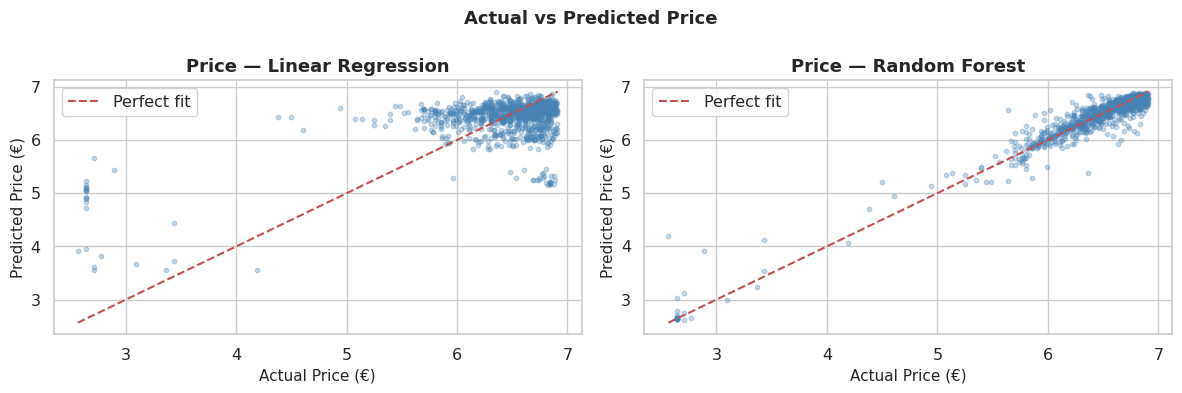

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, preds, title in zip(
    axes,
    [lr_preds, rf_preds],
    ["Linear Regression", "Random Forest"]
):
    ax.scatter(y_test, preds, alpha=0.3, s=10, color="steelblue")
    lims = [min(y_test.min(), preds.min()), max(y_test.max(), preds.max())]
    ax.plot(lims, lims, "r--", lw=1.5, label="Perfect fit")
    ax.set_xlabel("Actual Price (€)")
    ax.set_ylabel("Predicted Price (€)")
    ax.set_title(f"Price — {title}")
    ax.legend()

plt.suptitle("Actual vs Predicted Price", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("price_actual_vs_predicted.png", dpi=150)
plt.show()

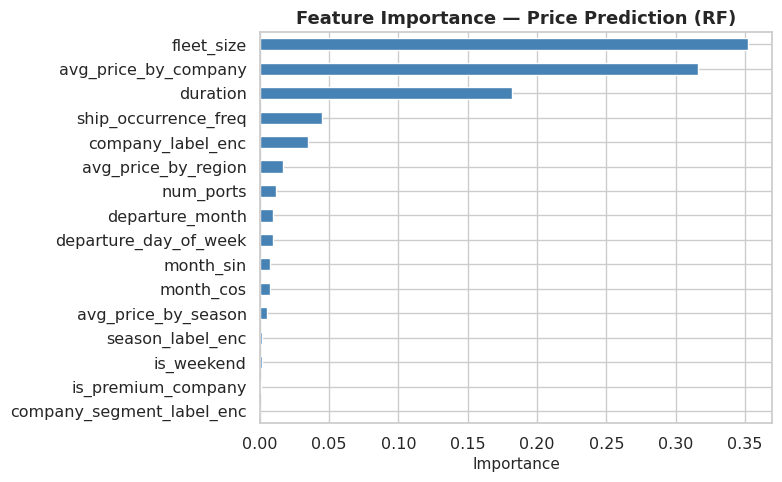

In [ ]:
importances = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()

plt.figure(figsize=(8, 5))
importances.plot(kind="barh", color="steelblue")
plt.title("Feature Importance — Price Prediction (RF)")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("price_feature_importance.png", dpi=150)
plt.show()

In [ ]:
# A new cruise to predict the price for
new_cruise = pd.DataFrame([{
    "duration": 7,
    "num_ports": 5,
    "departure_month": 6,
    "departure_day_of_week": 5,
    "is_weekend": 1,
    "fleet_size": 24,
    "ship_occurrence_freq": 150,
    "is_premium_company": 0,
    "month_sin": 0.866,
    "month_cos": -0.5,
    "avg_price_by_company": 67.0,
    "avg_price_by_season": 80.0,
    "avg_price_by_region": 47.0,
    "company_label_enc": 3,
    "season_label_enc": 2,
    "company_segment_label_enc": 0,
}])

predicted_price_log = rf.predict(new_cruise)[0]
predicted_price_real = np.expm1(predicted_price_log)

print(f"Predicted Price     : €{predicted_price_real:.2f}")

Predicted Price     : €650.23
